# Human players: strategy characterisation by centrality

Human players characterised by where they wait when a trial starts. This notebook covers the high-level strategy only. Differences within a strategy come later.

**The axis is centrality at slice onset**, `1 - r/R`, the same definition used for the RL agents (1 = arena centre, 0 = alcove back).

Each player plays a first solo, a social and a second solo session. Sessions are analysed separately, because the social context differs between them, and then compared.

**Plan**
1. Protocol across the timeline (session length and wall separations).
2. Trial-level split into central and peripheral trials, with one boundary fitted on social.
3. Social strategy types, from fixed cuts on the fraction of peripheral trials and from mixtures with k = 1-4 on player means.
4. Consistency across trials, including the effect of the previous trial.
5. Solo strategy types.
6. Change from first solo to social to second solo, including partner influence.

**Choices**
- The first solo drops its first 5 trials. Social and second solo keep every trial.
- One peripheral boundary, fitted on social trials, labels the trials of all three sessions.
- Players are treated as independent. The partner correlation is reported alongside.
- Fixed-cut labels (at most 20% peripheral trials = central, at least 80% = peripheral, otherwise mixed) are the working labels until the mixture results are reviewed. Switch with `WORKING_LABEL`.
- Everything that computes a number comes from `analysis/human_characterisation.py`, which reuses `analysis/model_characterisation.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from IPython.display import display
from scipy import stats

import data_extraction.data_saving as data_saving
import analysis.human_characterisation as hc

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

RECOMPUTE = False           # rebuild the cached tables and bootstrap
KS = (1, 2, 3, 4)           # mixture component counts to compare
# the labels every grouped plot and table below uses. 'fixed' counts each player's peripheral trials
# (at most 20% = central, at least 80% = peripheral, mixed in between) and fits nothing. 'gmm2' and 'gmm3'
# instead name each player after the mixture component that most likely produced their mean centrality,
# with no mixed group under gmm2 and an 'intermediate' one under gmm3
WORKING_LABEL = 'fixed'
N_BOOT = 200                # bootstrap resamples for the choice of k
N_PERM = 2000               # random-partner draws for the partner influence null
BIN_SIZE = 10               # trials per bin in the timeline
N_PERM_DRIFT = 1000         # block reorderings per player when testing for drift
DRIFT_CAP = 60              # trials social is capped at, to match the solos on length

LABELS = hc.SESSION_LABELS
STRAT_ORDER = ['central', 'mixed', 'peripheral']
# colours for mixture components, lowest centrality first (peripheral orange to central blue)
COMPONENT_COLOURS = {1: ['#555555'], 2: ['#DD8452', '#4C72B0'], 3: ['#DD8452', '#9E9E9E', '#4C72B0'],
                     4: ['#DD8452', '#E8B89A', '#9DB4D6', '#4C72B0']}

## Load data

Two tables are built once and cached.

**The onset table** holds one row per trial per player, measured at the frame the walls appear (slice onset). That frame ends the wait and starts the trial, so it is where a waiting strategy shows. Each row carries centrality, the raw x and z, the wall separation, who won the trial, and the same player's position when the previous trial ended.

**The session table** holds one row per session (100 social and 400 solo). It counts every trial logged, before any cut, so it describes the protocol rather than the trials analysed: trial count, duration, and the share of trials at each wall separation.

Throughout, an **experiment** is one pair on one day, holding their social session and their four solo sessions, while **session** always means one of first solo, social or second solo. Solo files are matched to experiments by position, and the check below confirms every solo file sits where its experiment and player predict.

In [2]:
# get the session file list and check each solo lines up with its experiment and player
social_paths, solo_paths = hc.session_files()
hc.check_file_alignment(social_paths, solo_paths)
experiments = hc.experiment_info(social_paths)

# build the onset table (one row per trial x player) and the session table (one row per session)
tables = hc.load_tables(recompute=RECOMPUTE)
onset, sessions = tables['onset'], tables['sessions']

print(f"{len(experiments)} experiments, {experiments['date'].min():%Y-%m-%d} to {experiments['date'].max():%Y-%m-%d}")
pd.DataFrame(dict(players=onset.drop_duplicates(['experiment', 'player', 'session_type']).groupby('session_type').size(),
                  trials=onset.groupby('session_type').size())).loc[list(hc.SESSION_TYPES)]

human_session_files: loaded from cache
human_onset_tables: loaded from cache
100 experiments, 2024-09-13 to 2026-03-30


,players,trials
session_type,,
solo1,200,9933
social,200,26479
solo2,200,11277


## 1. Protocol across the timeline

The protocol changed during data collection. Solo sessions in 2024 ran about half as many trials as later ones, and 2024 experiments used a different mix of wall separations. Later ones settle at about 50% one-wall, 25% two-wall and 25% four-wall trials. Everything is pooled below, so keep these differences in mind.

Both panels come from the session table, so trial counts include every trial logged, before the first-solo cut. Solo values average the two players.

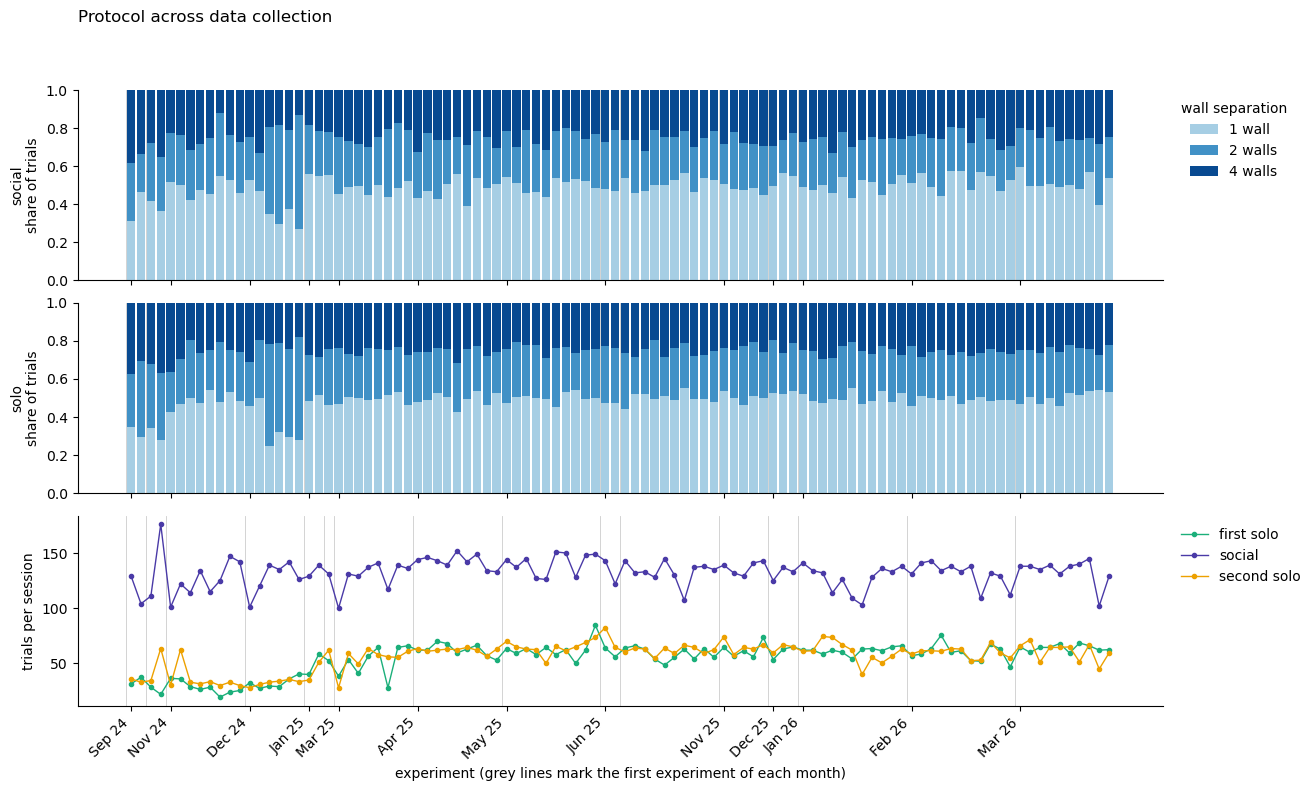

n_trials  duration_min  prop_sep_1  prop_sep_2  prop_sep_4
year session_type                                                            
2024 social           125.5         19.43        0.45        0.28        0.25
     solo1             30.0          6.19        0.42        0.31        0.26
     solo2             33.0          5.48        0.40        0.29        0.26
2025 social           137.0         20.63        0.50        0.25        0.25
     solo1             61.5         10.63        0.50        0.25        0.25
     solo2             63.0         10.27        0.49        0.26        0.25
2026 social           133.5         19.79        0.50        0.24        0.26
     solo1             62.0         10.70        0.50        0.25        0.25
     solo2             61.5          9.83        0.50        0.25        0.25

In [3]:
# get wall separation shares per experiment, for its social session and for the mean of its four solos
sep_cols = [f'prop_sep_{w}' for w in hc.WALL_SEPS if sessions[f'prop_sep_{w}'].sum() > 0]
social_sep = sessions[sessions['session_type'] == 'social'].set_index('experiment')[sep_cols]
solo_sep = sessions[sessions['session_type'] != 'social'].groupby('experiment')[sep_cols].mean()
n_trials = sessions.pivot_table(index='experiment', columns='session_type', values='n_trials', aggfunc='mean')

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True, gridspec_kw=dict(hspace=0.12))
sep_colours = plt.cm.Blues(np.linspace(0.35, 0.9, len(sep_cols)))

# plot stacked wall separation shares, one bar per experiment
for ax, table, name in ((axes[0], social_sep, 'social'), (axes[1], solo_sep, 'solo')):
    bottom = np.zeros(len(table))
    for col, colour in zip(sep_cols, sep_colours):
        ax.bar(table.index, table[col], bottom=bottom, width=0.85, color=colour,
               label=f"{col.rsplit('_', 1)[-1]} wall{'s' if col[-1] != '1' else ''}")
        bottom += table[col].to_numpy()
    ax.set_ylim(0, 1)
    ax.set_ylabel(f'{name}\nshare of trials')
axes[0].legend(title='wall separation', loc='upper left', bbox_to_anchor=(1.005, 1), frameon=False)

# plot the trial count of each session type
for st in hc.SESSION_TYPES:
    axes[2].plot(n_trials.index, n_trials[st], 'o-', ms=3, lw=1, color=hc.SESSION_PALETTE[st], label=LABELS[st])
axes[2].set_ylabel('trials per session')
axes[2].legend(loc='upper left', bbox_to_anchor=(1.005, 1), frameon=False)

# mark the first experiment of each month, labelling only months at least 3 experiments apart
month = experiments['date'].dt.to_period('M')
starts = experiments.loc[month != month.shift()]
labelled = []
for s in starts['experiment']:
    if not labelled or s - labelled[-1] >= 3:
        labelled.append(s)
for ax in axes:
    for s in starts['experiment']:
        ax.axvline(s - 0.5, color='#cccccc', lw=0.6, zorder=0)
    ax.spines[['top', 'right']].set_visible(False)
axes[2].set_xticks(labelled)
axes[2].set_xticklabels(experiments.loc[labelled, 'date'].dt.strftime('%b %y'), rotation=45, ha='right')
axes[2].set_xlabel('experiment (grey lines mark the first experiment of each month)')
fig.suptitle('Protocol across data collection', x=0.125, ha='left')
plt.show()

# get medians per year
(sessions.merge(experiments, on='experiment').assign(year=lambda d: d['date'].dt.year)
 .groupby(['year', 'session_type'])[['n_trials', 'duration_min'] + sep_cols].median().round(2))

**Interpretation**

- From 2025 the protocol is stable. Solos run about 60 trials over 10 minutes and social about 135 trials over 20 minutes. Trials split about 50/25/25 across one-, two- and four-wall separations.
- 2024 differs in two ways. Solos ran about half as many trials (30 to 33), and a few experiments (the first in September to October 2024, and a group around December 2024 to January 2025) used fewer one-wall trials.
- 2024 solo means are therefore built from fewer trials, and the 5-trial cut removes a larger share of their first solo.

## 2. Trial-level split

Individual trials divide into ones that start near a wall and ones that start near the centre, so each trial is labelled peripheral or central.

A **Gaussian mixture model with 2 components** is fitted to the onset centrality of every social trial, with all players pooled. Players contribute as many values as they have trials, so a player with more trials pulls the fit more.

The **boundary** is the centrality between the two component means at which the lower component stops being the more likely one. Trials below it count as peripheral. The label uses this single threshold rather than the model's own per-point assignment, which can send extreme values back to the wider component.

Each component is a bell curve that integrates to 1, describing the shape of that component alone, and a **weight**, the share of trials the model says that component produced. For a trial at a given centrality, the chance it came from a component is

`P(component | value) ∝ P(value | component) × weight`

normalised so the two components sum to 1. Density alone answers a different question, how likely that centrality is *within* a component, and ignores that one component holds more trials. The boundary is where the two weighted densities are equal, so a trial there is 50/50. It sits a little away from where the bare curves cross, pulled toward the lighter component.

One boundary labels the trials of all three sessions, so a peripheral trial means the same position in each. It is fitted on social, as social is the longest session and is played after some practice. The histograms of the two solos are shown against that same boundary.

This per-trial label feeds the fraction of peripheral trials per player, the fixed-cut labels, and the consistency checks in section 4.

**How many components.** This section fixes 2 components and does not test that number. Section 4a of `intermediate_strategy_characterisation.ipynb` (same folder) tests it on the same pooled social trials, with the spawn trial dropped. It fits beta mixtures, which suit a bounded and skewed measure better than Gaussians, with 2 and 3 shapes. Beta shapes fit far better than Gaussians with the same number of parameters (log likelihood 2063.5 against −313.5 with 2 shapes). 3 shapes have the lower BIC (−4684.6 against −4076.1), but the added shape is broad and flat (mean 0.41, SD 0.27) rather than a middle peak. So the extra shape describes the irregular wall end, and no middle waiting position is found.

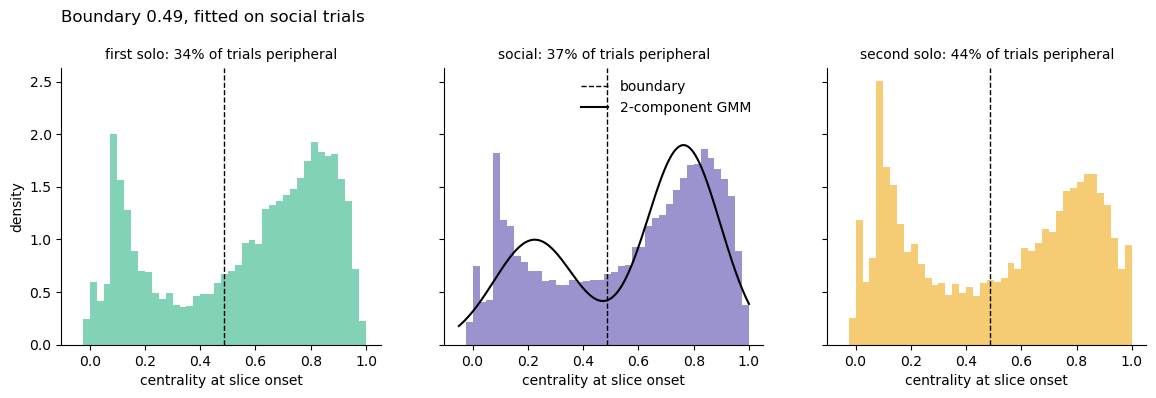

In [4]:
# fit the 2-component mixture on social trials, and flag every trial below its boundary as peripheral
onset, split = hc.fit_trial_split(onset)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
bins = np.linspace(-0.05, 1, 43)
grid = np.linspace(-0.05, 1, 300).reshape(-1, 1)
for ax, st in zip(axes, hc.SESSION_TYPES):
    sub = onset[onset['session_type'] == st]
    # plot the histogram of every trial and the shared boundary
    ax.hist(sub['centrality'], bins=bins, density=True, color=hc.SESSION_PALETTE[st], alpha=0.55)
    ax.axvline(split['boundary'], color='k', ls='--', lw=1, label='boundary')
    # plot the fitted mixture density on the session it was fitted to
    if st == split['reference']:
        ax.plot(grid, np.exp(split['gmm'].score_samples(grid)), color='k', lw=1.5, label='2-component GMM')
        ax.legend(frameon=False)
    ax.set_title(f"{LABELS[st]}: {sub['peripheral'].mean():.0%} of trials peripheral", fontsize=10)
    ax.set_xlabel('centrality at slice onset')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('density')
fig.suptitle(f"Boundary {split['boundary']:.2f}, fitted on {LABELS[split['reference']]} trials", x=0.125, y=1.04, ha='left')
plt.show()


**Interpretation**

- Onset positions are bimodal in every session. One peak sits near the walls (about 0.1, close to the wall face at 0.15) and the other near the centre (about 0.8).
- The middle range is not empty. Social is flat from about 0.2 to 0.5, so the boundary at 0.49 is where the fitted curves cross rather than a clear dip. Trials near it could reasonably go either way.
- The mixture follows the two peaks loosely. The wall peak is narrow and bounded at 0, which a Gaussian does not match well.
- With one boundary, the share of peripheral trials rises from 34% (first solo) to 37% (social) to 44% (second solo). Players wait at the walls more as the experiment goes on.

In [5]:
# reduce the onset table to one row per player per session type: mean, SD and median centrality,
# trial count, and the fraction of trials labelled peripheral in section 2
players = hc.player_table(onset)
players['fixed'] = hc.fixed_cut_labels(players['frac_peripheral'])

# fit a Gaussian mixture with each k to the player means, per session type, and name each player's component
fits = hc.fit_mixtures(players, ks=KS)
players = hc.add_mixture_labels(players, fits)
mix_table = hc.mixture_table(fits)


def label_order(col=None):
    """ Return the labels present in a column, ordered from central to peripheral.
        Takes a label column name, defaulting to the working label. """

    every = (['central', 'intermediate', 'mixed'] + [f'component {k}' for k in (4, 3, 2, 1)]
             + ['peripheral', 'unassigned'])
    present = set(players[col or WORKING_LABEL].dropna())
    return [lab for lab in every if lab in present]


def label_colour(lab):
    """ Return the plotting colour of a label. Takes the label. """

    return hc.STRAT_PALETTE.get(lab, '#777777')


WORKING_ORDER = label_order()
print(f"working labels ({WORKING_LABEL}): {WORKING_ORDER}")
players.head()

working labels (fixed): ['central', 'mixed', 'peripheral']


,experiment,player,session_type,mean_centrality,sd_centrality,median_centrality,n_trials,frac_peripheral,fixed,gmm1,gmm1_posterior,gmm2,gmm2_posterior,gmm3,gmm3_posterior,gmm4,gmm4_posterior
0,0,0,social,0.608795505,0.247825649,0.617575737,129,0.310077519,mixed,all,1.0,central,0.958914141,intermediate,0.733260654,component 3,0.922542751
1,0,0,solo1,0.179670594,0.118944426,0.145411432,25,0.960000000,peripheral,all,1.0,peripheral,0.999985856,peripheral,0.949124580,component 1,0.956119751
2,0,0,solo2,0.709937427,0.151579463,0.695545908,36,0.083333333,central,all,1.0,central,0.997523428,central,0.965432609,component 3,0.825712972
3,0,1,social,0.735651483,0.168731779,0.780647529,129,0.100775194,central,all,1.0,central,0.997328606,central,0.933166781,component 4,0.907121442
4,0,1,solo1,0.795261601,0.091510268,0.793280306,28,0.000000000,central,all,1.0,central,0.999959999,central,0.998477707,component 4,0.882566847


## 3. Social strategy types

### 3a. Player means and the fixed cut

The fixed cut counts each player's trial labels from section 2. A player is central if at most 20% of their trials are peripheral, peripheral if at least 80% are, and mixed otherwise. It needs no fitting, so it is the working label until the mixture results below are reviewed.

The left panel shows where each label sits on player mean centrality. The right panel shows that the two summaries track each other closely, so little is lost by counting trials instead of averaging them.

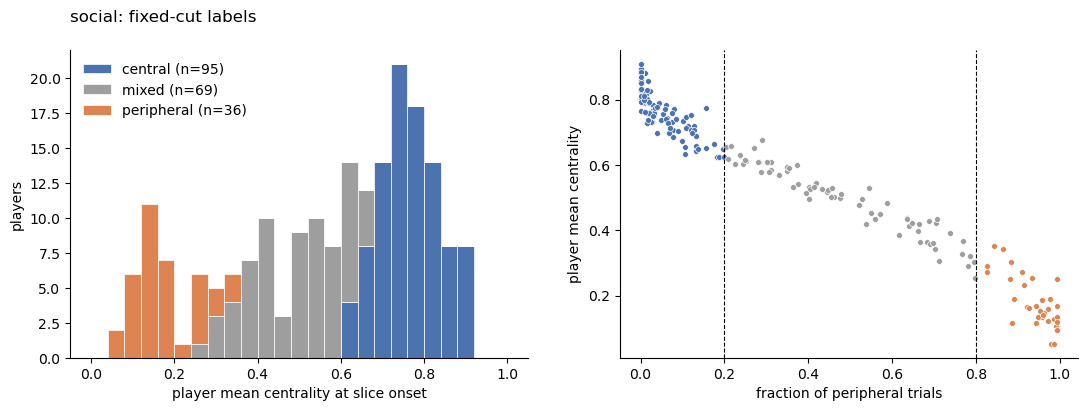

In [6]:
def plot_fixed_cut(st):
    """ Plot the fixed-cut labels two ways, as a histogram of player mean centrality and as mean
        centrality against the fraction of peripheral trials. Takes a session type.

        One point or one player in each panel. Dashed lines in the right panel mark the cuts. """

    sub = players[players['session_type'] == st]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    # plot a stacked histogram of player means by label
    bins = np.linspace(0, 1, 26)
    axes[0].hist([sub.loc[sub['fixed'] == lab, 'mean_centrality'] for lab in STRAT_ORDER], bins=bins, stacked=True,
                 color=[hc.STRAT_PALETTE[lab] for lab in STRAT_ORDER], edgecolor='white', linewidth=0.5,
                 label=[f"{lab} (n={(sub['fixed'] == lab).sum()})" for lab in STRAT_ORDER])
    axes[0].set_xlabel('player mean centrality at slice onset')
    axes[0].set_ylabel('players')
    axes[0].legend(frameon=False)

    # plot mean centrality against fraction of peripheral trials, with the cuts
    for lab in STRAT_ORDER:
        s = sub[sub['fixed'] == lab]
        axes[1].scatter(s['frac_peripheral'], s['mean_centrality'], s=18, color=hc.STRAT_PALETTE[lab],
                        edgecolor='white', linewidth=0.5, label=lab)
    for cut in hc.FIXED_CUTS:
        axes[1].axvline(cut, color='k', ls='--', lw=0.8)
    axes[1].set_xlabel('fraction of peripheral trials')
    axes[1].set_ylabel('player mean centrality')
    for ax in axes:
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(f'{LABELS[st]}: fixed-cut labels', x=0.125, ha='left')
    plt.show()


plot_fixed_cut('social')

**Interpretation**

- Player mean and fraction of peripheral trials track each other closely, so the fixed cut orders players almost exactly as their means do.
- Central players (95) form a tight group with means of 0.6 to 0.9. Peripheral players (36) sit at 0.05 to 0.35.
- Mixed players (69) fill the range between. Their mean alone cannot tell a player who mixes centre and wall from one who waits at intermediate positions (section 4c looks at how they mix).

#### Follow-up on mixed players

**The follow-up analysis is in `intermediate_strategy_characterisation.ipynb` (same folder).** It asks where mixed players wait, beyond how often they cross the boundary. It covers
- the mean and spread of each player's trials (exploratory),
- each player's own wall and centre positions and the gap between them, compared with one spread cut in two and with two separate positions, with block-redraw intervals,
- a soft centre weight per player from wall and centre shapes shared by all players, with a middle shape for comparison.

### 3b. Mixtures with k = 1-4

This fit works on **one value per player**, their mean onset centrality, rather than on trials. A Gaussian mixture is fitted to the 200 social players for each k, and a player is named after whichever component most likely produced them.

Curves show each component's density scaled by its weight, so they sum to the dotted total. The strip below each histogram places every player, coloured by component. Hollow markers are players whose top posterior is below 0.8, meaning the fit does not clearly place them in one component.

The posterior repeats the section 2 calculation on a player's mean rather than on a trial,

`P(component | player mean) ∝ P(player mean | component) × weight`

and the number reported is the largest across components. Read it as odds on that label: 0.8 is 4:1, 0.9 is 9:1, 0.95 is 19:1. A player falls below the cut when their mean sits in the overlap between components, where moving them to the neighbouring component barely changes how well the model fits. Those are the players whose label flips when the fit is redone on resampled data.

The cut is not comparable across k. The smallest possible top posterior is 1/k, so 0.50 at k = 2 but 0.25 at k = 4, and the same 0.8 asks more of the fit as k grows. Read each count next to its component means rather than against the other k.

BIC scores the fit against how many parameters it spends, and lower is better. It barely separates k here, so the bootstrap refits on resampled players and counts how often each k wins.

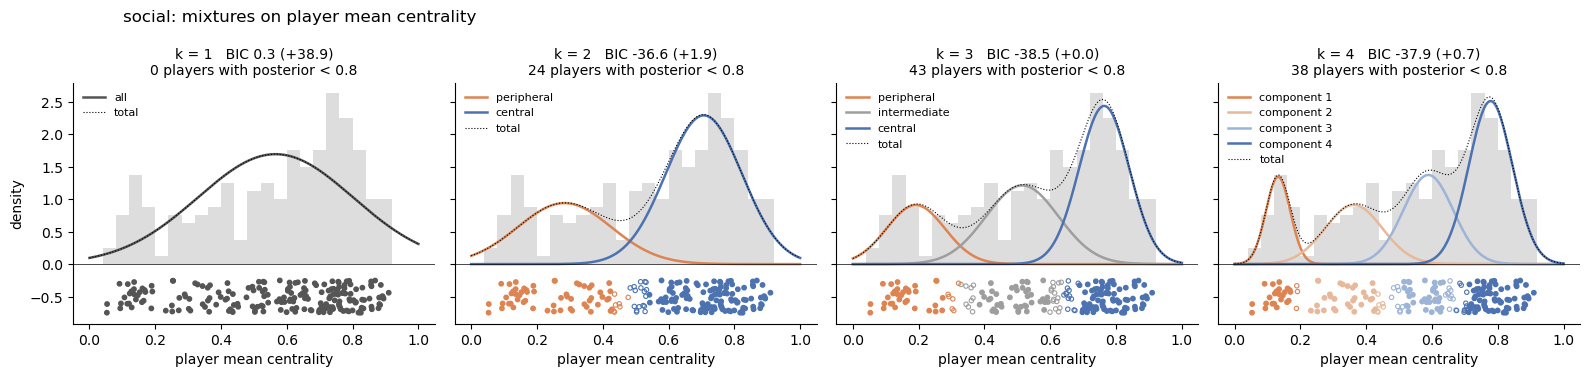

,session_type,bic,means,sds,weights
k,,,,,
1,social,0.329011754,[0.566],[0.236],[1.0]
2,social,-36.594470097,"[0.284, 0.707]","[0.142, 0.116]","[0.33, 0.67]"
3,social,-38.537599071,"[0.191, 0.515, 0.764]","[0.088, 0.11, 0.076]","[0.2, 0.33, 0.46]"
4,social,-37.856671280,"[0.132, 0.362, 0.589, 0.778]","[0.037, 0.087, 0.076, 0.066]","[0.12, 0.2, 0.26, 0.42]"


In [7]:
def plot_mixtures(st):
    """ Plot the distribution of player mean centrality with the fitted mixture for each k, one panel
        per k. Takes a session type.

        Grey bars are the players, coloured curves the weighted components, and the dotted line
        their total. Each panel titles its BIC, the gap to the best k, and how many players the
        fit places uncertainly. """

    sub = players[players['session_type'] == st]
    tab = mix_table[mix_table['session_type'] == st].set_index('k')
    fig, axes = plt.subplots(1, len(KS), figsize=(4 * len(KS), 3.8), sharey=True)
    bins = np.linspace(0, 1, 26)
    grid = np.linspace(0, 1, 300)

    for ax, k in zip(axes, KS):
        gmm = fits[st]['models'][k]
        order = np.argsort(gmm.means_.ravel())
        colours = COMPONENT_COLOURS[k]
        # plot the histogram of player means as a density
        ax.hist(sub['mean_centrality'], bins=bins, density=True, color='#dddddd')
        # plot each weighted component, lowest centrality first
        for rank, comp in enumerate(order):
            pdf = gmm.weights_[comp] * stats.norm.pdf(grid, gmm.means_.ravel()[comp],
                                                      np.sqrt(gmm.covariances_.ravel()[comp]))
            ax.plot(grid, pdf, color=colours[rank], lw=1.8, label=hc.component_names(k)[rank])
        ax.plot(grid, np.exp(gmm.score_samples(grid.reshape(-1, 1))), color='k', lw=0.8, ls=':', label='total')

        # plot each player below the axis, hollow where the top posterior is below 0.8
        names = list(hc.component_names(k))
        y = -0.25 - 0.5 * np.random.default_rng(0).random(len(sub))
        colour = [colours[names.index(n)] for n in sub[f'gmm{k}']]
        sure = sub[f'gmm{k}_posterior'].to_numpy() >= hc.POSTERIOR_MIN
        ax.scatter(sub['mean_centrality'][sure], y[sure], s=10, c=np.array(colour, dtype=object)[sure].tolist())
        ax.scatter(sub['mean_centrality'][~sure], y[~sure], s=10, facecolors='none',
                   edgecolors=np.array(colour, dtype=object)[~sure].tolist(), linewidths=0.8)

        ax.axhline(0, color='k', lw=0.5)
        ax.set_title(f"k = {k}   BIC {tab.loc[k, 'bic']:.1f} ({tab.loc[k, 'bic'] - tab['bic'].min():+.1f})\n"
                     f"{(~sure).sum()} players with posterior < {hc.POSTERIOR_MIN}", fontsize=10)
        ax.set_xlabel('player mean centrality')
        ax.legend(frameon=False, fontsize=8, loc='upper left')
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('density')
    fig.suptitle(f'{LABELS[st]}: mixtures on player mean centrality', x=0.08, ha='left')
    plt.tight_layout()
    plt.show()
    display(tab.drop(columns='aic'))


plot_mixtures('social')

**Interpretation**

- One component fits badly (39 BIC points worse than the best). Social players are not one group.
- k = 2, 3 and 4 fit almost equally well (within 2 BIC points), so the data do not pick a number of groups.
- The k = 3 middle component sits at 0.52, where the fixed-cut mixed players are. Between 24 and 43 players have a posterior below 0.8 for every k above 1, so the edges between groups are not sharp.
- The distribution reads more as two peaks with a broad spread between than as well-separated groups.

**What a player mean near the middle means.** A mean near 0.5 can come from a player who alternates between the wall and centre peaks, or from one whose trials spread across the middle. The mixture on means cannot tell these apart. Section 3a of `intermediate_strategy_characterisation.ipynb` (same folder) tests it by splitting each player's trials at the boundary and comparing the gap between the two sides with the spread within them. In social, the median intermediate player's gap is 0.41 (3.35 × SD), between the one-spread references (2.65 to 3.46 × SD). Two positions give 0.65 (5.88 × SD). Only 2 of 69 social intermediate players reach the two-position reference. So most players behind the k = 3 middle component are not alternating between the two peaks. Their values do not separate one broad spread from two broad, overlapping positions.

#### The bootstrap

Each round draws 200 players at random from the 200 recorded, **with replacement**. Some players come up two or three times and about a third are left out, so every round is a full-size sample that differs from the real one. It stands in for running the study again with a different set of participants, which is the thing a single BIC cannot tell you about.

That is what the BIC column above needs. Social BIC separates k = 2, 3 and 4 by under 2 points, a gap well inside what a change of participants could move. Refitting each k on every round and counting the winners turns "k = 3 fits best here" into how often k = 3 would fit best at all. A k winning 195 rounds and a k winning 120 report the same single best k and mean different things.

**Two caveats.** Partners are drawn independently, so the two players of an experiment can be split or duplicated separately. Their means correlate at 0.59 in social, so the true spread across samples is wider than the counts suggest. A player drawn twice also contributes two identical values, which slightly favours fitting extra narrow components.

In [8]:
# count how often each k has the lowest BIC across bootstrap resamples of players
boot = data_saving.cached('human_bootstrap_best_k', lambda: hc.bootstrap_best_k(players, ks=KS, n_boot=N_BOOT),
                          recompute=RECOMPUTE, stamp=dict(n_boot=N_BOOT, ks=KS, n_players=len(players)))
boot.loc[list(hc.SESSION_TYPES)]

human_bootstrap_best_k: loaded from cache


,1,2,3,4
session_type,,,,
solo1,0,135,50,15
social,0,40,123,37
solo2,0,33,147,20


**Interpretation**

- No session supports a single group.
- The first solo favours 2 components (135 of 200 rounds). Social and second solo favour 3 (123 and 147 rounds).
- The social preference for 3 is weak, as it loses 77 of 200 rounds. This matches its small BIC margin.
- A middle group may appear after the first solo, but other explanations fit too. 2024 first solos keep only about 25 trials after the cut. The second solo also follows social in time, so the change cannot be tied to playing together alone.

### 3c. How the labelling methods compare

This is not a change across sessions. Every table uses the same 200 players in the same social session, and labels each player twice, once with each of two methods. Rows give the label from one method and columns the label from the other.

A player on the diagonal gets the same label from both methods. A player off the diagonal is labelled differently depending only on the method chosen, as their trials are identical. The off-diagonal counts therefore show how much the choice of method changes who counts as central, mixed or peripheral.

The three methods are
- `fixed`, the fraction of peripheral trials (at most 20% = central, at least 80% = peripheral, mixed in between),
- `gmm2`, the most likely of 2 mixture components fitted to player means (section 3b),
- `gmm3`, the same with 3 components.

**Everything below runs on `WORKING_LABEL`, set in the first cell, currently the fixed cut.** Switching it to `gmm2` or `gmm3` changes every grouped plot and table that follows, including the transitions across sessions in 6b.

What to expect if it changes. `gmm2` has no middle group, so each of the 69 mixed players is named central (41) or peripheral (28), whichever component is more likely for their mean. Group means separate further apart, transitions become a 2 x 2 table, and a player whose mean sits near the edge between the two components changes label after a small shift. `gmm3` gives much the same groups as the fixed cut here (60 of the 69 mixed players fall in its intermediate group). But its edges are set by the fit rather than by a rule, so they move when the set of players changes. The fixed cut is the only method whose edges stay put when the data change.

In [9]:
soc = players[players['session_type'] == 'social']
for a, b in (('fixed', 'gmm2'), ('fixed', 'gmm3'), ('gmm2', 'gmm3')):
    print(f"{a} (rows) vs {b} (columns)")
    display(pd.crosstab(soc[a], soc[b], margins=True))

fixed (rows) vs gmm2 (columns)


gmm2,central,peripheral,All
fixed,,,
central,95,0,95
mixed,41,28,69
peripheral,0,36,36
All,136,64,200


fixed (rows) vs gmm3 (columns)


gmm3,central,intermediate,peripheral,All
fixed,,,,
central,91,4,0,95
mixed,4,60,5,69
peripheral,0,2,34,36
All,95,66,39,200


gmm2 (rows) vs gmm3 (columns)


gmm3,central,intermediate,peripheral,All
gmm2,,,,
central,95,41,0,136
peripheral,0,25,39,64
All,95,66,39,200


**Interpretation**

- The fixed cut and gmm3 give the same label to 185 of 200 social players.
- The methods agree on almost every fixed-cut central and peripheral player (125 of 131 under gmm3, all 131 under gmm2).
- The disagreement is mostly about mixed players. gmm2 has no middle group and names them central (41) or peripheral (28), which makes its central group much broader.
- The choice of method matters most for anything built on the mixed group, such as the transition tables in 6b.

### 3d. Partners

Players are treated as independent above, but the two players of an experiment shared its social session. The first solo gives a baseline, as the pair have not played together yet, so any rise from the first solo to social is what playing together adds.

Agreement is how often both players of an experiment carry the same label. Chance is what that agreement would be if players were paired at random, which is high whenever one label is common.

first solo   partner r = +0.18  (p = 0.077, 100 pairs)
social       partner r = +0.59  (p = 7.3e-11, 100 pairs)
second solo  partner r = +0.47  (p = 6.1e-07, 100 pairs)


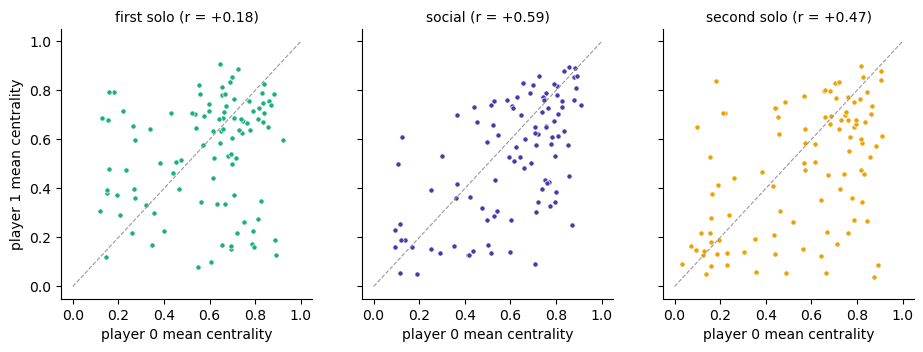

,session_type,agreement,chance,n_pairs,label
0,solo1,0.44,0.39,100,fixed
1,social,0.51,0.38,100,fixed
2,solo2,0.56,0.35,100,fixed
0,solo1,0.67,0.57,100,gmm2
1,social,0.74,0.56,100,gmm2
2,solo2,0.70,0.51,100,gmm2
0,solo1,0.53,0.46,100,gmm3
1,social,0.49,0.37,100,gmm3
2,solo2,0.54,0.37,100,gmm3


In [10]:
corr = hc.partner_correlation(players)
for row in corr.itertuples():
    print(f"{LABELS[row.session_type]:<12} partner r = {row.r:+.2f}  (p = {row.p:.2g}, {row.n_pairs} pairs)")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5), sharex=True, sharey=True)
for ax, st in zip(axes, hc.SESSION_TYPES):
    w = players[players['session_type'] == st].pivot(index='experiment', columns='player', values='mean_centrality')
    ax.scatter(w[0], w[1], s=14, color=hc.SESSION_PALETTE[st], edgecolor='white', linewidth=0.5)
    ax.plot([0, 1], [0, 1], color='#999999', lw=0.8, ls='--')
    r = corr.set_index('session_type').loc[st, 'r']
    ax.set_title(f'{LABELS[st]} (r = {r:+.2f})', fontsize=10)
    ax.set_xlabel('player 0 mean centrality')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('player 1 mean centrality')
plt.show()

pd.concat([hc.partner_agreement(players, lab).assign(label=lab) for lab in ('fixed', 'gmm2', 'gmm3')]).round(2)

**Interpretation**

- Partners' means barely correlate in the first solo (r = 0.18, p = 0.08). They correlate strongly in social (r = 0.59), and still do in the second solo (r = 0.47), when they no longer play together.
- Label agreement shows the same pattern. Under the fixed cut, partners agree 44% of the time in the first solo against 39% by chance. This rises to 51% (chance 38%) in social and 56% (chance 35%) in the second solo.
- Partners become more alike once they play together, and the similarity outlasts the social session. The next check asks how much was already there in the first solo.

#### Are partners alike before playing together?

Partners usually do not know each other and cannot discuss the game before playing. Similarity in the first solo therefore cannot come from playing together, but it does matter for every partner comparison below.

The gap is the distance between the two players' first-solo means, averaged over experiments. The null pairs each experiment's player 0 with another experiment's player 1, 2000 times. A real gap below the null means partners are already alike.

The right panel keeps only 2026 experiments, where every session ran the same protocol (trial counts, durations and wall separation shares).

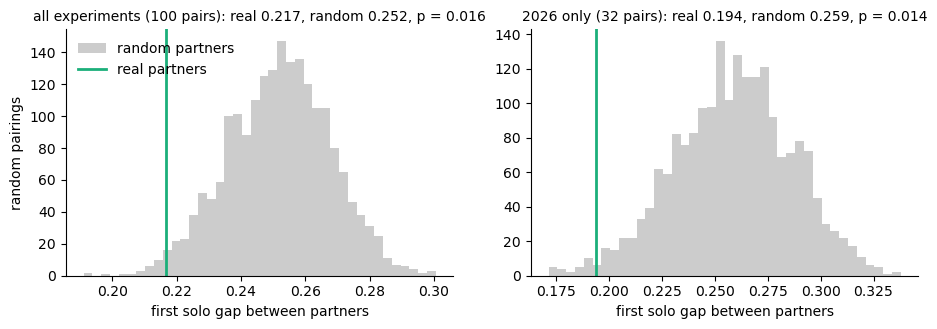

In [11]:
# get the first-solo gap between partners against random pairings, for every experiment and for 2026 only
recent = experiments.loc[experiments['date'].dt.year == 2026, 'experiment']
subsets = {'all experiments': players, '2026 only': players[players['experiment'].isin(recent)]}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for ax, (name, sub) in zip(axes, subsets.items()):
    res = hc.partner_gap_null(sub, 'solo1', n_perm=N_PERM)
    # plot the random-pairing gaps with the real gap
    ax.hist(res['null'], bins=40, color='#cccccc', label='random partners')
    ax.axvline(res['gap'], color=hc.SESSION_PALETTE['solo1'], lw=2, label='real partners')
    ax.set_title(f"{name} ({res['n_pairs']} pairs): real {res['gap']:.3f}, "
                 f"random {res['null'].mean():.3f}, p = {res['p']:.3f}", fontsize=10)
    ax.set_xlabel('first solo gap between partners')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('random pairings')
axes[0].legend(frameon=False)
plt.show()


Partners are already closer than random pairs in the first solo, before any shared play (0.217 against 0.252, p = 0.016). The 2026 experiments show the same (0.194 against 0.259, p = 0.014, 32 pairs). The first-solo partner correlation is weak (r = 0.18, and 0.35 in 2026), but every later partner comparison starts from this similarity rather than from none.

## 4. Consistency across trials

Do players keep one waiting position, or switch between centre and periphery? A player mean hides the difference, so four views test it directly.

- **Raster.** One row per player, sorted by mean centrality, and one column per trial. The strip on the left is the fixed-cut label. Reading along a row shows whether a player held one position or moved between them.
- **Fraction of peripheral trials against a shared-rate null.** The null gives every player the same underlying rate and their own trial count, then draws their trials at random. Observed fractions more spread than the null mean players genuinely differ, rather than all sampling one common habit.
- **Split-half reliability.** Correlation between player means computed on odd and on even trials, then on the first and second half of the session. Odd-even measures noise, first-second also picks up drift. Spearman-Brown corrects for each half holding only half the trials.
- **Runs.** How often consecutive trials carry the same label, observed and with each player's own trials shuffled. Above the shuffled rate means the labels arrive in runs rather than trial by trial.

Section 4b then asks the related question over a longer stretch, whether a player's position moves across the session as a whole. Section 4c asks whether mixed players alternate between positions or switch once.

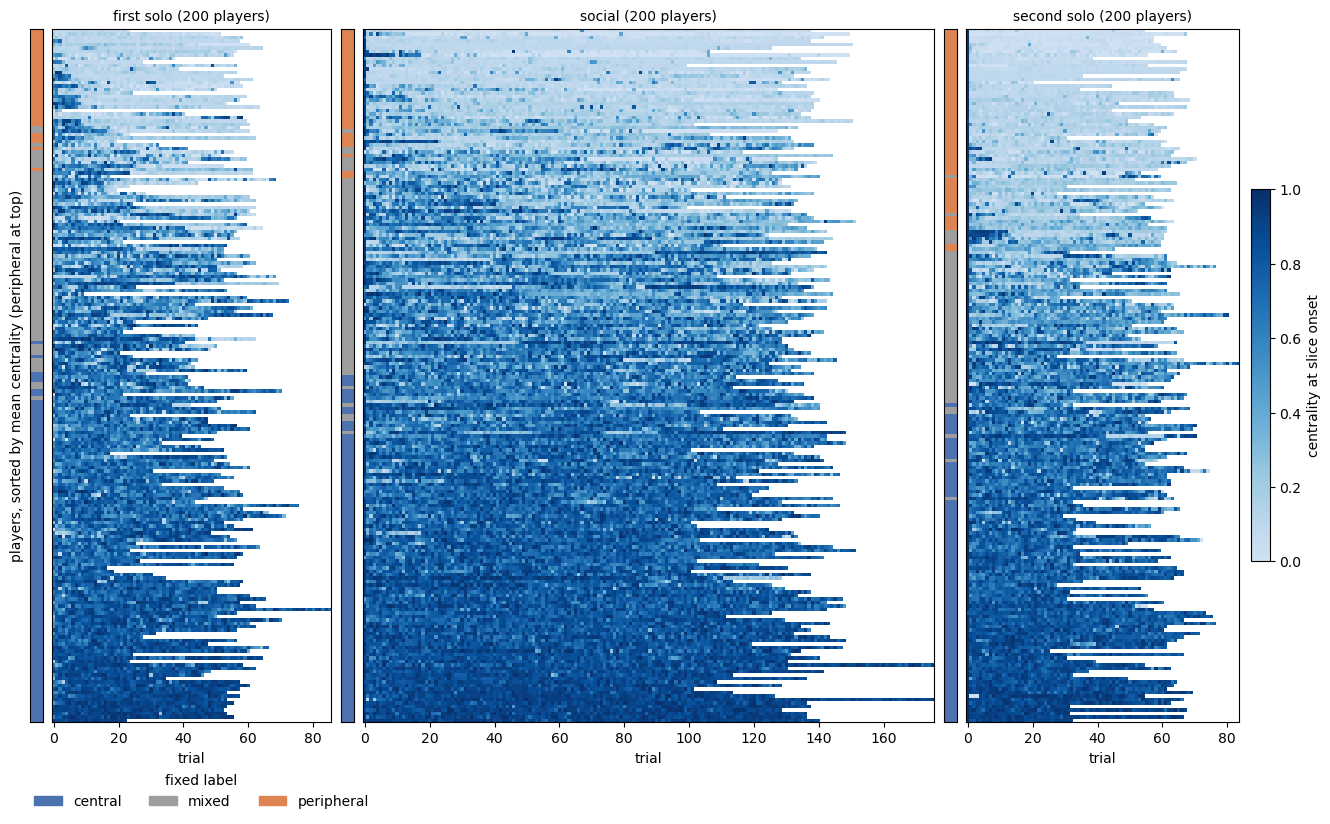

In [12]:
cmap = mcolors.LinearSegmentedColormap.from_list('centrality', plt.cm.Blues(np.linspace(0.2, 1, 256)))
cmap.set_bad('white')
label_cmap = mcolors.ListedColormap([label_colour(lab) for lab in WORKING_ORDER])

rasters = {st: hc.raster(onset, st) for st in hc.SESSION_TYPES}
widths = []
for st in hc.SESSION_TYPES:
    widths += [4, rasters[st][0].shape[1]]
fig, axes = plt.subplots(1, 6, figsize=(16, 9), gridspec_kw=dict(width_ratios=widths, wspace=0.05))

for i, st in enumerate(hc.SESSION_TYPES):
    mat, order = rasters[st]
    # get each player's fixed-cut label in raster order, and draw it as a colour strip beside the rows
    lab = order.merge(players[players['session_type'] == st], on=['experiment', 'player'])[WORKING_LABEL]
    codes = lab.map({l: j for j, l in enumerate(WORKING_ORDER)}).to_numpy(float).reshape(-1, 1)
    axes[2 * i].imshow(codes, aspect='auto', cmap=label_cmap, vmin=-0.5, vmax=len(WORKING_ORDER) - 0.5,
                       interpolation='nearest')
    axes[2 * i].set_xticks([])
    axes[2 * i].set_yticks([])
    im = axes[2 * i + 1].imshow(mat, aspect='auto', cmap=cmap, vmin=0, vmax=1, interpolation='nearest')
    axes[2 * i + 1].set_yticks([])
    axes[2 * i + 1].set_title(f'{LABELS[st]} ({len(order)} players)', fontsize=10)
    axes[2 * i + 1].set_xlabel('trial')
axes[0].set_ylabel('players, sorted by mean centrality (peripheral at top)')
fig.colorbar(im, ax=axes, fraction=0.015, pad=0.01, label='centrality at slice onset')
handles = [plt.Rectangle((0, 0), 1, 1, color=label_colour(l)) for l in WORKING_ORDER]
fig.legend(handles, WORKING_ORDER, title=f'{WORKING_LABEL} label', loc='lower left', ncol=3, frameon=False,
           bbox_to_anchor=(0.12, 0.0))
plt.show()

**Interpretation**

- Most players hold one position for most of a session. Rows at the top stay light (wall) and rows at the bottom stay dark (centre).
- Mixed players, in the middle rows, move between the two in runs rather than trial by trial.
- Many players start a session nearer the centre than they continue. On average the first 3 trials are 0.18 more central than the rest of the second solo (87% of players), and 0.12 more central in social (71%). The first solo shows no such effect, but its first 5 trials are cut. This may reflect where players are when a session begins, which is worth checking.
- Rows end at different points because session lengths differ, most clearly between 2024 and later solos.

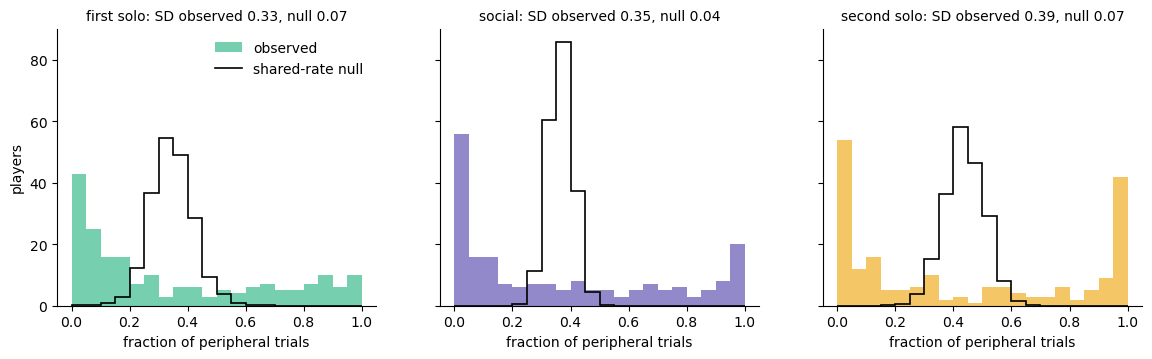

,session_type,split,r,spearman_brown,n_players
0,solo1,odd_even,0.980,0.990,200
1,solo1,first_second,0.783,0.878,200
2,social,odd_even,0.996,0.998,200
3,social,first_second,0.874,0.933,200
4,solo2,odd_even,0.992,0.996,200
5,solo2,first_second,0.923,0.960,200


In [13]:
null = hc.frac_peripheral_null(players)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
bins = np.linspace(0, 1, 21)
for ax, st in zip(axes, hc.SESSION_TYPES):
    obs = players.loc[players['session_type'] == st, 'frac_peripheral']
    # get the mean histogram across simulated sessions
    null_counts = np.mean([np.histogram(sim, bins=bins)[0] for sim in null[st]], axis=0)
    ax.hist(obs, bins=bins, color=hc.SESSION_PALETTE[st], alpha=0.6, label='observed')
    ax.stairs(null_counts, bins, color='k', lw=1.2, label='shared-rate null')
    ax.set_title(f'{LABELS[st]}: SD observed {obs.std():.2f}, null {null[st].std(axis=1).mean():.2f}', fontsize=10)
    ax.set_xlabel('fraction of peripheral trials')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('players')
axes[0].legend(frameon=False)
plt.show()

hc.split_half(onset).round(3)

**Interpretation**

- Players differ far more than a shared habit allows. The observed spread of the fraction of peripheral trials is 5 to 9 times the null.
- The observed distributions are U-shaped, with most players near 0 or 1. The null is a single narrow peak.
- The peak at 1 grows in the second solo (42 players with almost all trials peripheral, against 10 in the first solo). The peak at 0 is also a little higher after the first solo (43 to 54-56).
- Player means are highly consistent within a session (odd-even r = 0.98 to 0.996). Splitting in alternating blocks of 10, which keeps runs within one half, gives nearly the same (0.95 to 0.99).
- The first-second split is lower, most of all in the first solo (r = 0.78, against 0.87 in social and 0.92 in the second solo). Players change position within a session, most in the first solo.

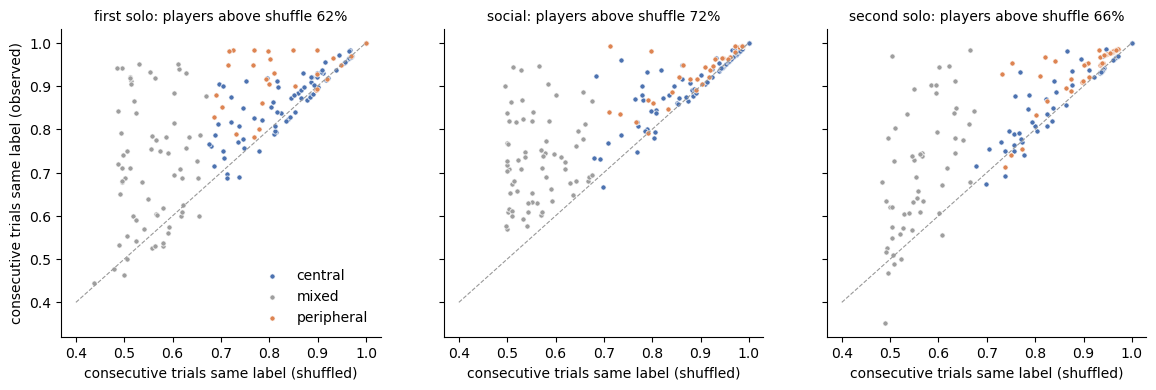

p_same  p_same_shuffled   diff
session_type fixed                                     
solo1        central      0.899            0.875  0.023
             mixed        0.715            0.555  0.160
             peripheral   0.931            0.845  0.085
social       central      0.926            0.905  0.020
             mixed        0.729            0.562  0.167
             peripheral   0.936            0.897  0.039
solo2        central      0.918            0.905  0.012
             mixed        0.703            0.562  0.141
             peripheral   0.949            0.919  0.031

In [14]:
runs = hc.run_consistency(onset).merge(players[['experiment', 'player', 'session_type', WORKING_LABEL]],
                                       on=['experiment', 'player', 'session_type'])

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, st in zip(axes, hc.SESSION_TYPES):
    sub = runs[runs['session_type'] == st]
    for lab in WORKING_ORDER:
        s = sub[sub[WORKING_LABEL] == lab]
        ax.scatter(s['p_same_shuffled'], s['p_same'], s=14, color=label_colour(lab),
                   edgecolor='white', linewidth=0.5, label=lab)
    ax.plot([0.4, 1], [0.4, 1], color='#999999', lw=0.8, ls='--')
    ax.set_title(f"{LABELS[st]}: players above shuffle {(sub['p_same'] > sub['p_same_shuffled']).mean():.0%}",
                 fontsize=10)
    ax.set_xlabel('consecutive trials same label (shuffled)')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('consecutive trials same label (observed)')
axes[0].legend(frameon=False)
plt.show()

# summarise observed against shuffled per label
(runs.assign(diff=lambda d: d['p_same'] - d['p_same_shuffled'])
 .groupby(['session_type', WORKING_LABEL])[['p_same', 'p_same_shuffled', 'diff']].mean()
 .loc[list(hc.SESSION_TYPES)].round(3))

**Interpretation**

- 62 to 72% of players repeat their label on consecutive trials more often than shuffled order predicts. Trials come in runs.
- The excess is largest for mixed players (0.14 to 0.17 above shuffled). Central and peripheral players rarely change label, which leaves little room above shuffled.
- The shuffle removes slow drift as well as short runs, so part of this excess comes from players shifting position across the session (section 4b).

### 4a. Win-stay, lose-shift (social)

Does the outcome of a trial change where a player waits on the next one? Each pair of consecutive trials gives a **change**, this trial's onset centrality minus the previous trial's, and the previous trial's outcome splits the pairs. Positive means the player moved toward the centre.

Two measures per player, each an average over their own trials.
- **Signed change** (`d_win`, `d_loss`) gives the direction of the move.
- **Absolute change** (`abs_win`, `abs_loss`) gives its size, whatever the direction. This is the win-stay, lose-shift reading, as a player who stays put after a win has a small `abs_win`.

The two can disagree, and that is informative. A player who moves far in both directions after a loss has a large absolute change and a signed change near 0.

The right panel plots the within-player difference, as a player who moves a lot anyway has a large absolute change after either outcome. `shift_diff = abs_loss − abs_win` is above 0 for a player who moves further after losing.

Solo players always reach a wall, so this needs the social session. Only consecutive pairs count, so a trial without a slice onset breaks the pair (200 of 26,479 trials). Players need at least 10 trials of each outcome.

**Two checks, because an outcome effect can be leftover position rather than a choice.**
- Conditioning on the outcome could pick out where the player was standing, if players win more often from some positions. `coef_won` repeats the comparison with the previous onset held fixed (the coefficient of the previous win in `onset ~ previous onset + previous win`). The previous onset is only 0.005 more central before wins than before losses, so this changes little.
- The winner ends the trial at the wall it triggered, so a win leaves the player further out. `coef_won_ctrl` adds where the previous trial ended (`onset ~ previous onset + previous trial end + previous win`), and `abs_won_ctrl` does the same for the size of the move (`|change| ~ |previous trial end − previous onset| + previous win`). This is the check that matters.

The left panel keeps the earlier check, each player's mean onset centrality after a win against after a loss.

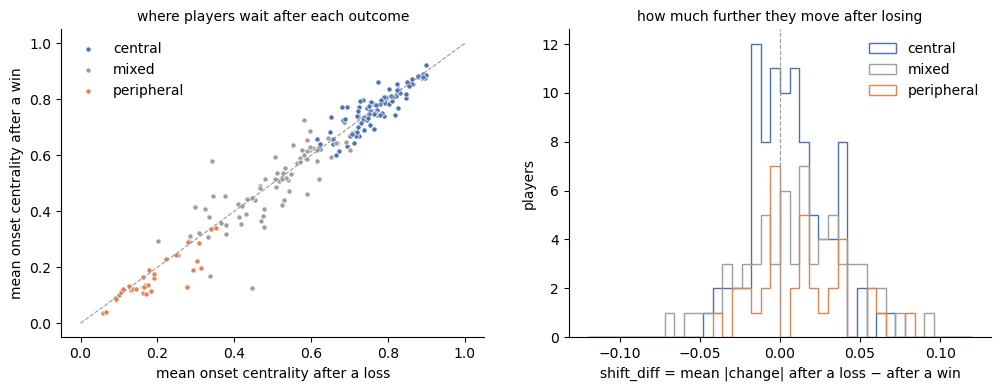

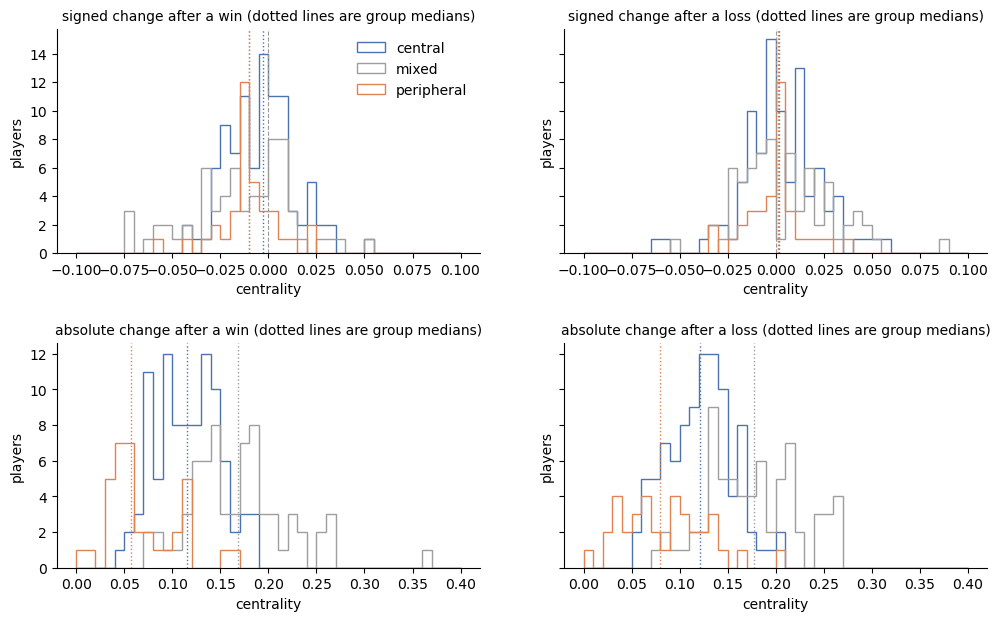

mean onset after win - after loss: median -0.006  (Wilcoxon p = 0.045, n = 200)
signed change after a win: median -0.0080, d = -0.28, 35% of players above 0 (Wilcoxon p = 2e-07, n = 198)
signed change after a loss: median +0.0014, d = +0.17, 53% of players above 0 (Wilcoxon p = 0.079, n = 198)
abs_loss - abs_win: median +0.0080, d = +0.27, 60% of players above 0 (Wilcoxon p = 7.1e-05, n = 198)
d_loss - d_win: median +0.0095, d = +0.26, 61% of players above 0 (Wilcoxon p = 0.00031, n = 198)
previous win, previous onset held fixed: median -0.0075, d = -0.18, 39% of players above 0 (Wilcoxon p = 0.0045, n = 198)
previous win, previous onset and trial end held fixed: median -0.0042, d = -0.02, 43% of players above 0 (Wilcoxon p = 0.37, n = 198)
previous trial end, in the same fit: median +0.2159, d = +1.25, 92% of players above 0 (Wilcoxon p = 2.9e-32, n = 198)
previous win on the size of the move, trial end held fixed: median -0.0028, d = -0.20, 44% of players above 0 (Wilcoxon p = 0.026,

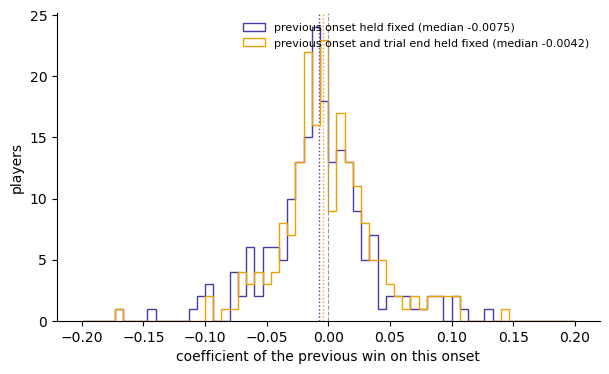

,d_win,d_loss,abs_win,abs_loss,shift_diff,coef_won,coef_won_ctrl,abs_won_ctrl
fixed,,,,,,,,
central,-0.003,0.002,0.116,0.122,0.003,-0.003,-0.005,-0.002
mixed,-0.010,0.001,0.168,0.177,0.012,-0.010,-0.006,-0.009
peripheral,-0.010,0.001,0.057,0.080,0.013,-0.014,-0.001,0.001


In [15]:
# get each player's mean onset centrality after a win and after a loss, and their trial-to-trial changes
prev = hc.previous_trial_effect(onset).merge(
    players.loc[players['session_type'] == 'social', ['experiment', 'player', WORKING_LABEL]],
    on=['experiment', 'player'])
wsls = hc.wsls_metrics(onset).merge(
    players.loc[players['session_type'] == 'social', ['experiment', 'player', WORKING_LABEL]],
    on=['experiment', 'player'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# plot mean onset centrality after a win against after a loss
for lab in WORKING_ORDER:
    s = prev[prev[WORKING_LABEL] == lab]
    axes[0].scatter(s['after_loss'], s['after_win'], s=14, color=label_colour(lab),
                    edgecolor='white', linewidth=0.5, label=lab)
axes[0].plot([0, 1], [0, 1], color='#999999', lw=0.8, ls='--')
axes[0].set_xlabel('mean onset centrality after a loss')
axes[0].set_ylabel('mean onset centrality after a win')
axes[0].set_title('where players wait after each outcome', fontsize=10)
axes[0].legend(frameon=False)

# plot the within-player difference in how far they move
for lab in WORKING_ORDER:
    axes[1].hist(wsls.loc[wsls[WORKING_LABEL] == lab, 'shift_diff'], bins=np.linspace(-0.12, 0.12, 41),
                 histtype='step', lw=1.5, color=label_colour(lab), label=lab)
axes[1].axvline(0, color='#999999', lw=0.8, ls='--')
axes[1].set_xlabel('shift_diff = mean |change| after a loss − after a win')
axes[1].set_ylabel('players')
axes[1].set_title('how much further they move after losing', fontsize=10)
axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

# plot the change after each outcome, signed on top and absolute below
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey='row', gridspec_kw=dict(hspace=0.4))
panels = ((0, 'd_win', 'signed change after a win', np.linspace(-0.1, 0.1, 41)),
          (1, 'd_loss', 'signed change after a loss', np.linspace(-0.1, 0.1, 41)),
          (2, 'abs_win', 'absolute change after a win', np.linspace(0, 0.4, 41)),
          (3, 'abs_loss', 'absolute change after a loss', np.linspace(0, 0.4, 41)))
for k, col, title, bins in panels:
    ax = axes[k // 2, k % 2]
    for lab in WORKING_ORDER:
        s = wsls.loc[wsls[WORKING_LABEL] == lab, col]
        ax.hist(s, bins=bins, histtype='step', lw=1.5, color=label_colour(lab), label=lab)
        ax.axvline(s.median(), color=label_colour(lab), lw=1, ls=':')
    if col.startswith('d_'):
        ax.axvline(0, color='#999999', lw=0.8, ls='--')
    ax.set_title(f'{title} (dotted lines are group medians)', fontsize=10)
    ax.set_xlabel('centrality')
    ax.set_ylabel('players')
    ax.spines[['top', 'right']].set_visible(False)
axes[0, 0].legend(frameon=False)
plt.show()

# test each measure across players, and the win minus loss difference
d = (prev['after_win'] - prev['after_loss']).dropna()
print(f"mean onset after win - after loss: median {d.median():+.3f}  (Wilcoxon p = {stats.wilcoxon(d).pvalue:.2g}, n = {len(d)})")
for col, name in (('d_win', 'signed change after a win'), ('d_loss', 'signed change after a loss'),
                  ('shift_diff', 'abs_loss - abs_win'), ('direction_diff', 'd_loss - d_win'),
                  ('coef_won', 'previous win, previous onset held fixed'),
                  ('coef_won_ctrl', 'previous win, previous onset and trial end held fixed'),
                  ('b_end', 'previous trial end, in the same fit'),
                  ('abs_won_ctrl', 'previous win on the size of the move, trial end held fixed')):
    v = wsls[col].dropna()
    d = v.mean() / v.std()
    print(f"{name}: median {v.median():+.4f}, d = {d:+.2f}, {(v > 0).mean():.0%} of players above 0 "
          f"(Wilcoxon p = {stats.wilcoxon(v).pvalue:.2g}, n = {len(v)})")
print(f"typical move for scale: median |change| after a win = {wsls['abs_win'].median():.3f}")

# plot the win coefficient before and after holding the previous trial end fixed
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(-0.2, 0.2, 61)
for col, colour, name in (('coef_won', '#4a3aa7', 'previous onset held fixed'),
                          ('coef_won_ctrl', '#eda100', 'previous onset and trial end held fixed')):
    v = wsls[col].dropna()
    ax.hist(v, bins=bins, histtype='step', lw=1.8, color=colour,
            label=f'{name} (median {v.median():+.4f})')
    ax.axvline(v.median(), color=colour, lw=1, ls=':')
ax.axvline(0, color='#999999', lw=0.8, ls='--')
ax.set_xlabel('coefficient of the previous win on this onset')
ax.set_ylabel('players')
ax.legend(frameon=False, fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

wsls.groupby(WORKING_LABEL)[['d_win', 'd_loss', 'abs_win', 'abs_loss', 'shift_diff',
                             'coef_won', 'coef_won_ctrl', 'abs_won_ctrl']].median().round(3)


**Interpretation**

**The outcome of a trial does not reliably change where a player waits next. The apparent effects are tiny and track where the previous trial left the player.**

- **Every outcome effect is small next to a normal move.** A typical trial-to-trial move is 0.125 in centrality. The largest outcome effect is 0.008, about 6% of one move and under 1% of the centrality range. Across players the effects sit at d = 0.2 to 0.3, and only 60% of players fall on the expected side of 0. The small p values come from 198 players and 26,279 trial pairs, not from a large effect.
- **The wallward pull after a win disappears once the previous trial end is held fixed.** The win coefficient goes from −0.0075 (p = 0.004) to −0.0042 (p = 0.37, d = −0.02). Where the previous trial ended is itself a strong predictor of the next onset (0.216, p = 3 × 10⁻³², 92% of players above 0). The winner ends at the wall they triggered, and part of that carries into the next trial.
- **The lose-shift shrinks the same way.** Holding fixed how far the previous trial ended from that trial's onset, the extra movement after a loss falls from +0.0080 to +0.0028, about 2% of a typical move.
- **What survives is inertia, not strategy.** The best predictor of where a player waits next is where the last trial left them, and the outcome adds little once that is known.
- **Group differences in how much players move are large and do not depend on the outcome.** Peripheral players move least (absolute change 0.057 after a win), central players more (0.116) and mixed players most (0.168), which follows from mixed players using both positions.
- **Two cautions on the control.** Trial-end positions are the frames most affected by the logged overshoot past walls in social, and player 1's positions come through the network. Drift across the session also adds to these changes, though it cannot explain a difference between outcomes within the same player.

### 4b. Drift within a session

A player mean assumes one fixed strategy for the whole session. The social session runs a median of 134 trials and is a player's first exposure to an opponent, so a player could plausibly start one way and finish another.

The question here is how much players drift as a group. It is answered from each player's own trial order, against a null that reorders their trials **in blocks of 10**. Whole blocks move and the order inside a block is kept, so a player's runs of one strategy survive and only the slow trend is destroyed. Shuffling single trials would count those runs as drift, and section 4 showed the runs are real. Runs longer than 10 trials are still broken up, so they count as drift here.

**Group measures** (first table)
- **p_group** compares the mean |second half − first half| across players with the same mean in each of 1000 reorderings. It asks whether players drift at all.
- **drift_rms** is the typical size of real drift in centrality units. It is the root mean square of the half differences, with the part that reordering alone produces taken away. It counts drift that all players share as well as drift that differs between them.
- **mean_half** is the average half difference, and gives the shared direction (negative = toward the wall).

**Per-player measures** (second table and plots)
- **half_diff**, the second half's mean minus the first half's.
- **step** and **step_at**, the largest difference any split of the session makes and where it falls, which separates one switch from a slow slide.
- **slope**, an ordinary least squares fit in centrality per 100 trials.
- **flagged_half** and **flagged_step** count players whose own test gives p < 0.05. These p values are **uncorrected**, so about 5% of players pass even with no drift (`expected_by_chance`). A longer session gives each test more power, so the counts cannot be compared across sessions. They are shown only against chance.

Social is also measured on its first 60 trials only, so its drift can be read next to the solos at a similar length.

In [16]:
# get each player's drift measures, for every trial and for social capped at the solo length
drift = data_saving.cached('human_drift', lambda: hc.within_session_drift(onset, n_perm=N_PERM_DRIFT),
                           recompute=RECOMPUTE, stamp=dict(n_perm=N_PERM_DRIFT, rows=len(onset)))
drift_capped = data_saving.cached(
    'human_drift_capped',
    lambda: hc.within_session_drift(onset, session_types=('social',), max_trials=DRIFT_CAP, n_perm=N_PERM_DRIFT),
    recompute=RECOMPUTE, stamp=dict(n_perm=N_PERM_DRIFT, cap=DRIFT_CAP, rows=len(onset)))

# get the group drift measures for the same two sets
group = data_saving.cached('human_group_drift', lambda: hc.group_drift(onset, n_perm=N_PERM_DRIFT),
                           recompute=RECOMPUTE, stamp=dict(n_perm=N_PERM_DRIFT, rows=len(onset)))
group_capped = data_saving.cached(
    'human_group_drift_capped',
    lambda: hc.group_drift(onset, session_types=('social',), max_trials=DRIFT_CAP, n_perm=N_PERM_DRIFT),
    recompute=RECOMPUTE, stamp=dict(n_perm=N_PERM_DRIFT, cap=DRIFT_CAP, rows=len(onset)))

capped_name = f'social (first {DRIFT_CAP})'
print('group drift')
display(pd.concat([group, group_capped.rename(index={'social': capped_name})]).round(3))
print('per-player measures, with uncorrected flag counts against chance')
display(pd.concat([hc.drift_summary(drift), hc.drift_summary(drift_capped).rename(index={'social': capped_name})]).round(3))


human_drift: loaded from cache
human_drift_capped: loaded from cache
human_group_drift: loaded from cache
human_group_drift_capped: loaded from cache
group drift


,players,mean_half,mean_abs_half,mean_abs_half_reordered,p_group,rms_observed,rms_reordered,drift_rms
session_type,,,,,,,,
solo1,194,-0.034,0.113,0.076,0.001,0.169,0.109,0.129
social,200,-0.031,0.087,0.042,0.001,0.129,0.060,0.115
solo2,200,-0.028,0.070,0.056,0.001,0.109,0.082,0.072
social (first 60),200,-0.016,0.081,0.059,0.001,0.119,0.085,0.083


per-player measures, with uncorrected flag counts against chance


,players,median_abs_half,median_slope,flagged_half,flagged_step,share_big,expected_by_chance
session_type,,,,,,,
solo1,194,0.066,-0.019,25,27,0.366,9.7
social,200,0.050,-0.025,70,42,0.305,10.0
solo2,200,0.046,-0.120,18,18,0.225,10.0
social (first 60),200,0.055,-0.049,15,22,0.290,10.0


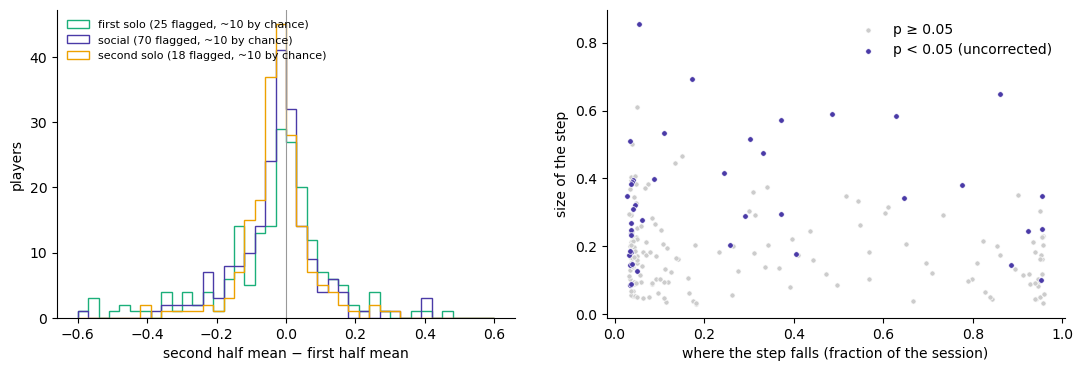

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# plot how far each player moved between the halves of their session
for st in hc.SESSION_TYPES:
    sub = drift[drift['session_type'] == st]
    axes[0].hist(sub['half_diff'], bins=np.linspace(-0.6, 0.6, 41), histtype='step', lw=1.8,
                 color=hc.SESSION_PALETTE[st],
                 label=f"{LABELS[st]} ({(sub['p_half'] < 0.05).sum()} flagged, ~{0.05 * len(sub):.0f} by chance)")
axes[0].axvline(0, color='#999999', lw=0.8)
axes[0].set_xlabel('second half mean − first half mean')
axes[0].set_ylabel('players')
axes[0].legend(frameon=False, fontsize=8, loc='upper left')

# plot where each social player's largest step falls, and how big it is
soc = drift[drift['session_type'] == 'social']
# flag players whose largest step beats their own null (p_step < 0.05, from hc.within_session_drift).
# The null is built per player. Their trials are cut into blocks of 10, and the blocks are put in a random order
# (order inside each block kept) 1000 times. Each reordering is split at every point with at least 5 trials on
# either side, and the largest |after mean - before mean| is kept. p_step is the share of reorderings whose
# largest step is at least the real one. Taking the largest over every split point in the null as well stops the
# search for the best split from passing as a real step. p_step is uncorrected, so about 5% of players (~10 of 200)
# pass by chance, and grey vs coloured is not a reliable split of individual players
flagged = soc['p_step'] < 0.05
axes[1].scatter(soc.loc[~flagged, 'step_at'], soc.loc[~flagged, 'step'].abs(), s=14, color='#cccccc',
                edgecolor='white', linewidth=0.5, label='p ≥ 0.05')
axes[1].scatter(soc.loc[flagged, 'step_at'], soc.loc[flagged, 'step'].abs(), s=16,
                color=hc.SESSION_PALETTE['social'], edgecolor='white', linewidth=0.5, label='p < 0.05 (uncorrected)')
axes[1].set_xlabel('where the step falls (fraction of the session)')
axes[1].set_ylabel('size of the step')
axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

#### Do partners converge during the social session?

If drift comes from meeting an opponent, the two players of an experiment should grow more alike as the session runs. Each session is cut into ten equal stretches of its own length, and the gap is the distance between the pair's mean centrality in a stretch.

The null pairs each experiment's player 0 with another experiment's player 1, so it holds any tendency for players to drift the same way regardless of whom they faced. A gap below the null means partners resemble each other, and a falling gap means they converge while playing.

human_partner_gap: loaded from cache


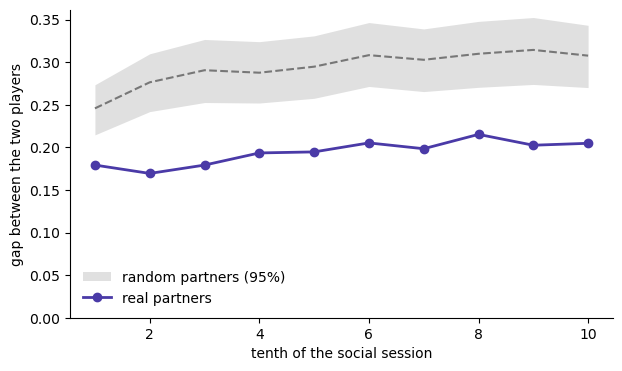

gap slope +0.0040 per tenth (null mean +0.0059), p = 0.199, 100 pairs
first tenth: real 0.179 vs random 0.246   last tenth: real 0.205 vs random 0.308


In [18]:
pg = data_saving.cached('human_partner_gap', lambda: hc.partner_gap_over_session(onset, n_perm=N_PERM),
                        recompute=RECOMPUTE, stamp=dict(n_perm=N_PERM, rows=len(onset)))

fig, ax = plt.subplots(figsize=(7, 4))
lo, hi = np.percentile(pg['null_gaps'], [2.5, 97.5], axis=0)
ax.fill_between(pg['bins'] + 1, lo, hi, color='#cccccc', alpha=0.6, lw=0, label='random partners (95%)')
ax.plot(pg['bins'] + 1, pg['null_gap'], color='#777777', lw=1.5, ls='--')
ax.plot(pg['bins'] + 1, pg['gap'], color=hc.SESSION_PALETTE['social'], lw=2, marker='o', label='real partners')
ax.set_xlabel('tenth of the social session')
ax.set_ylabel('gap between the two players')
ax.set_ylim(0)
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

print(f"gap slope {pg['slope']:+.4f} per tenth (null mean {pg['null_slopes'].mean():+.4f}), p = {pg['p']:.3f}, "
      f"{pg['n_pairs']} pairs")
print(f"first tenth: real {pg['gap'][0]:.3f} vs random {pg['null_gap'][0]:.3f}   "
      f"last tenth: real {pg['gap'][-1]:.3f} vs random {pg['null_gap'][-1]:.3f}")

#### What the drift analysis shows

- **Players drift in every session.** The group test beats the block reordering in all three sessions and in social capped at 60 trials (p = 0.001, the smallest possible with 1000 reorderings).
- **Drift is largest in the first solo and smallest in the second.** The typical size of real drift (drift_rms) is 0.13 in the first solo, 0.08 in social over its first 60 trials, and 0.07 in the second solo. Over all its trials social reaches 0.12, as a longer session leaves more room to move.
- **Flag counts reflect power, not the amount of drift.** Social flags 70 players on the half split against about 10 by chance, and the solos flag 25 and 18. But social has the smallest reordering spread (0.06, against 0.08 to 0.11 in the solos), because it has the most trials. Its test picks up smaller moves, so it flags more players without having more drift.
- **The drift runs toward the wall.** The mean half difference is negative in every session (−0.03), and 55 to 68% of players end nearer the wall than they started. Part of this is the more central start of each session seen in the section 4 raster.
- **Largest steps sit near the session start.** In social, 47% of all players have their largest step in the first 10% of the session, and the flagged players do not differ (52%). This fits settling in over the opening trials. The largest step of a random series also tends to fall near an end, so the location alone is weak evidence.
- **Partners do not converge while playing.** The gap between the two players holds flat or widens slightly, matching the random-partner null. But real partners already sit closer than random pairs in the first tenth of the session (0.179 against 0.246) and stay there. Part of that similarity is present before they play together (section 3d), and the rest is in place within the opening trials rather than building over the session.

### 4c. Alternating or switching once

A mixed player can reach their fraction of peripheral trials two ways. They can move between centre and wall throughout the session, or hold one position and then switch to the other. Both give the same fraction and the same mean.

The **switch score** separates them. It counts how often a player's label changes between consecutive trials, divided by the count expected if their trials came in random order. With k peripheral trials out of n, random order gives `2k(n − k) / n` changes on average.

- A score near 0 means few changes and long runs, as a single switch gives.
- A score near 1 means the player moves between positions as if at random.
- A score above 1 means they alternate more often than random order would.

Players who hold one label throughout have no expected changes and are left out. The score is least stable for players with only a few trials of one label, so the histograms keep to players with between 20% and 80% peripheral trials (the fixed-cut mixed range).

Colour marks players whose largest step gave p < 0.05 in the block-reordering test in 4b. A switcher should have both a low score and a step. These p values are uncorrected (about 5% of players pass by chance), so colour is read across groups of players rather than for any one player. Players with fewer than 20 trials have no step test and are shown in grey.

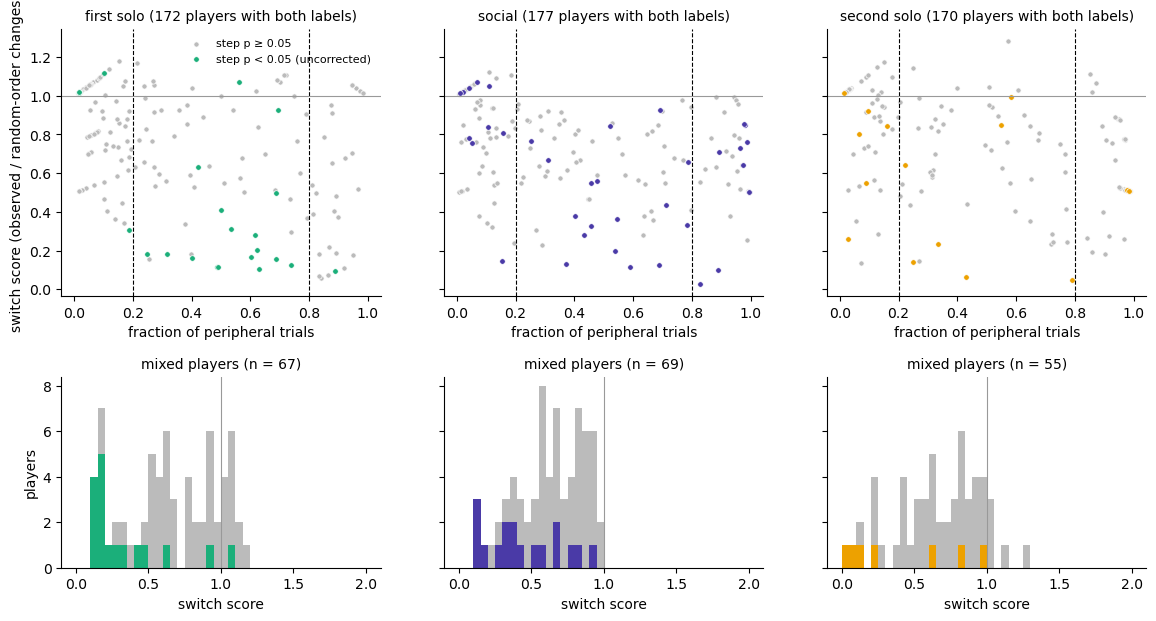

,players,median_score,share_below_half,share_above_one,share_stepped
session_type,,,,,
solo1,67,0.63,0.30,0.16,0.25
social,69,0.66,0.28,0.00,0.25
solo2,55,0.70,0.27,0.09,0.13


In [19]:
# get each player's switch score, with their step test from 4b
keys = ['experiment', 'player', 'session_type']
sw = (hc.switch_score(onset).merge(drift[keys + ['p_step', 'step_at']], on=keys, how='left')
      .assign(stepped=lambda d: d['p_step'] < 0.05,
              mixed=lambda d: hc.fixed_cut_labels(d['frac_peripheral']) == 'mixed'))
sw = sw[sw['switch_score'].notna()]

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex='row', sharey='row',
                         gridspec_kw=dict(height_ratios=[1.4, 1], hspace=0.35))
score_bins = np.linspace(0, 2, 41)
for i, st in enumerate(hc.SESSION_TYPES):
    sub = sw[sw['session_type'] == st]
    step = sub['stepped']
    # plot switch score against the fraction of peripheral trials
    ax = axes[0, i]
    ax.scatter(sub.loc[~step, 'frac_peripheral'], sub.loc[~step, 'switch_score'], s=14, color='#bbbbbb',
               edgecolor='white', linewidth=0.5, label='step p ≥ 0.05')
    ax.scatter(sub.loc[step, 'frac_peripheral'], sub.loc[step, 'switch_score'], s=16,
               color=hc.SESSION_PALETTE[st], edgecolor='white', linewidth=0.5, label='step p < 0.05 (uncorrected)')
    for cut in hc.FIXED_CUTS:
        ax.axvline(cut, color='k', ls='--', lw=0.8)
    ax.axhline(1, color='#999999', lw=0.8)
    ax.set_title(f'{LABELS[st]} ({len(sub)} players with both labels)', fontsize=10)
    ax.set_xlabel('fraction of peripheral trials')

    # plot the switch scores of mixed players, split by the uncorrected step test
    ax = axes[1, i]
    mixed = sub[sub['mixed']]
    ax.hist([mixed.loc[mixed['stepped'], 'switch_score'], mixed.loc[~mixed['stepped'], 'switch_score']],
            bins=score_bins, stacked=True, color=[hc.SESSION_PALETTE[st], '#bbbbbb'],
            label=['step p < 0.05 (uncorrected)', 'step p ≥ 0.05'])
    ax.axvline(1, color='#999999', lw=0.8)
    ax.set_title(f'mixed players (n = {len(mixed)})', fontsize=10)
    ax.set_xlabel('switch score')
for ax in axes.ravel():
    ax.spines[['top', 'right']].set_visible(False)
axes[0, 0].set_ylabel('switch score (observed / random-order changes)')
axes[1, 0].set_ylabel('players')
axes[0, 0].legend(frameon=False, fontsize=8)
plt.show()

# summarise mixed players per session
(sw[sw['mixed']].groupby('session_type')
 .agg(players=('switch_score', 'size'), median_score=('switch_score', 'median'),
      share_below_half=('switch_score', lambda v: (v < 0.5).mean()),
      share_above_one=('switch_score', lambda v: (v > 1).mean()),
      share_stepped=('stepped', 'mean'))
 .loc[list(hc.SESSION_TYPES)].round(2))


/tmp/ipykernel_1205870/778172437.py:8: PerformanceWarning: indexing past lexsort depth may impact performance.
  trials = sub.loc[(e, p)]


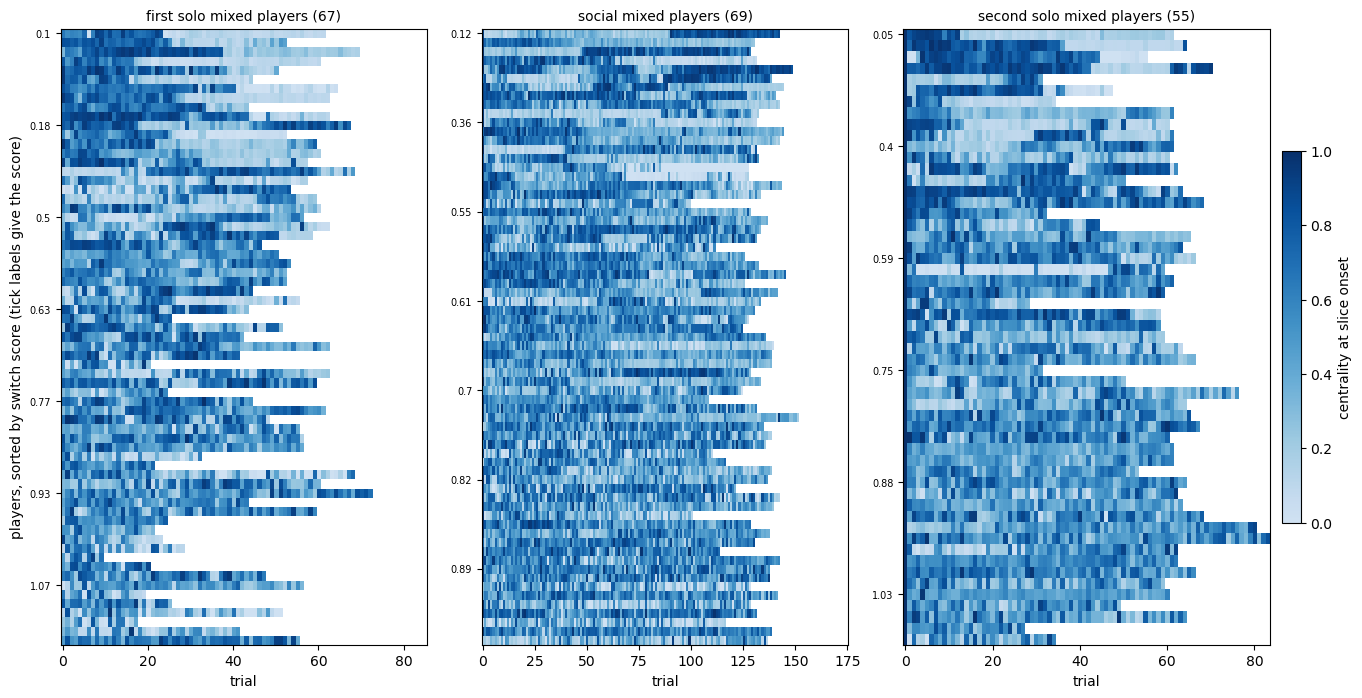

In [20]:
# plot every mixed player's trials, sorted by switch score (lowest at top)
fig, axes = plt.subplots(1, 3, figsize=(16, 8), gridspec_kw=dict(wspace=0.15))
for ax, st in zip(axes, hc.SESSION_TYPES):
    mixed = sw[(sw['session_type'] == st) & sw['mixed']].sort_values('switch_score')
    sub = onset[onset['session_type'] == st].set_index(['experiment', 'player'])
    mat = np.full((len(mixed), int(sub['trial_pos'].max()) + 1), np.nan)
    for row, (e, p) in enumerate(zip(mixed['experiment'], mixed['player'])):
        trials = sub.loc[(e, p)]
        mat[row, trials['trial_pos'].to_numpy(int)] = trials['centrality'].to_numpy()
    im = ax.imshow(mat, aspect='auto', cmap=cmap, vmin=0, vmax=1, interpolation='nearest')
    # mark the score of every tenth row
    ticks = np.arange(0, len(mixed), 10)
    ax.set_yticks(ticks)
    ax.set_yticklabels(mixed['switch_score'].to_numpy()[ticks].round(2), fontsize=7)
    ax.set_title(f'{LABELS[st]} mixed players ({len(mixed)})', fontsize=10)
    ax.set_xlabel('trial')
axes[0].set_ylabel('players, sorted by switch score (tick labels give the score)')
fig.colorbar(im, ax=axes, fraction=0.015, pad=0.01, label='centrality at slice onset')
plt.show()


#### What the switch score shows

- **Most mixed players come in runs, but few switch only once.** The median score is 0.63 to 0.70 in all three sessions, below the random-order level of 1. About 28% of mixed players score below 0.5.
- **Only the first solo shows a separate group of switchers.** Its mixed players have a cluster at 0.1 to 0.2. 70% of those scoring below 0.5 give a step with p < 0.05, against 6% of higher scorers, so as a group the low scorers switch. The step test is uncorrected, so this does not pick out which individual players switched. Their step falls about halfway through the session, and 80% of the steps run toward the wall. In the raster these players start central and end peripheral.
- **Social and second solo show no gap.** Scores spread evenly from about 0.1 to 1. Low scores there mostly mean several long runs rather than one switch (53% and 27% of low scorers give a step with p < 0.05, against 14% and 8% of higher scorers).
- **Few players alternate faster than random order.** None do in social, and the solo players who do mostly have short sessions.
- **Session length matters in the first solo.** Shorter first solos give higher scores (Spearman −0.49 between score and trial count), so 2024 players with 20 to 25 trials count as alternators more easily.

So "switching once" describes a subset of first-solo mixed players, mostly moving from centre to wall. In social and second solo, mixed players move between positions in runs of varying length.

## 5. Solo strategy types

The same fixed cut and the same mixtures, refitted on the first and second solo. Solo players have no opponent, so these labels describe the player alone, and the social labels can be read against them.

The last figure overlays the three session types on one axis, for player means and for the fraction of peripheral trials.

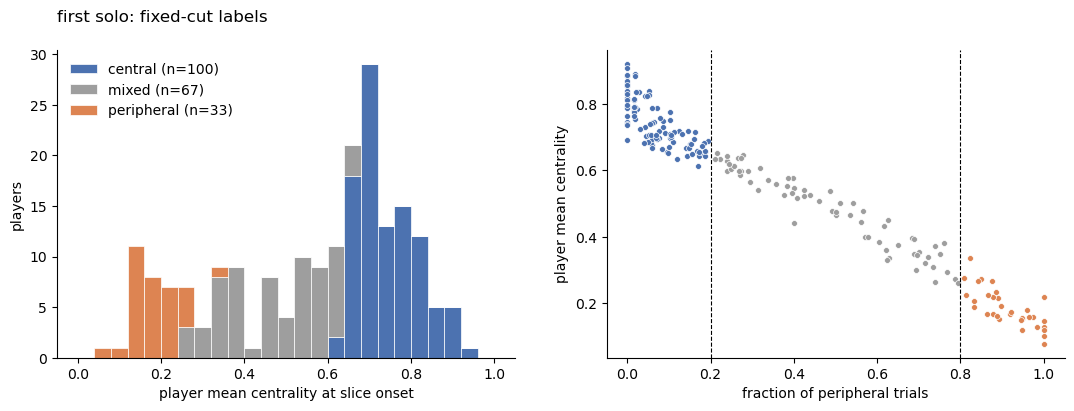

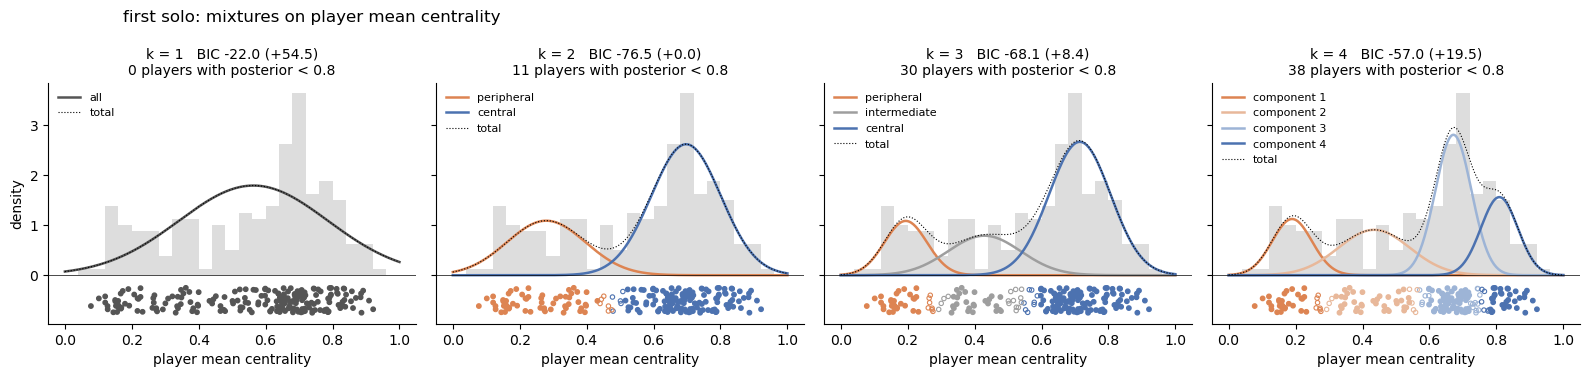

,session_type,bic,means,sds,weights
k,,,,,
1,solo1,-22.045172972,[0.564],[0.223],[1.0]
2,solo1,-76.523834570,"[0.279, 0.697]","[0.117, 0.104]","[0.32, 0.68]"
3,solo1,-68.107461096,"[0.194, 0.429, 0.714]","[0.063, 0.109, 0.092]","[0.17, 0.22, 0.61]"
4,solo1,-56.996777904,"[0.189, 0.435, 0.672, 0.809]","[0.059, 0.106, 0.054, 0.055]","[0.17, 0.24, 0.38, 0.21]"


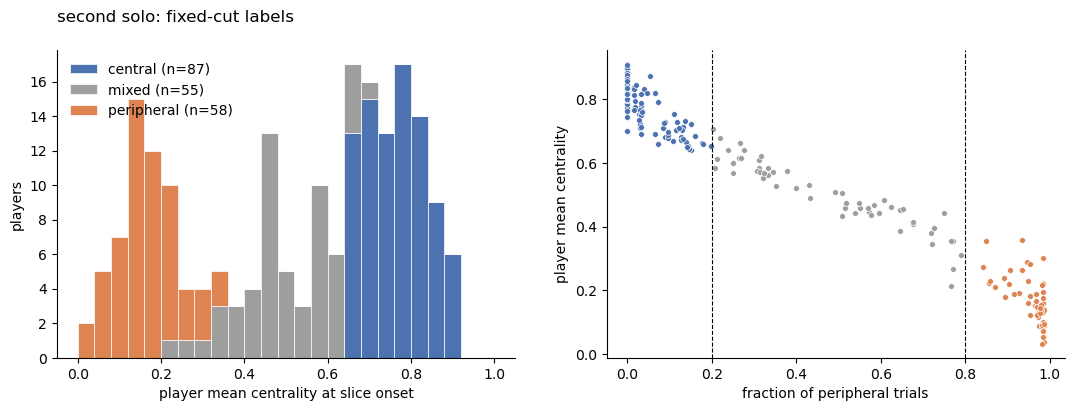

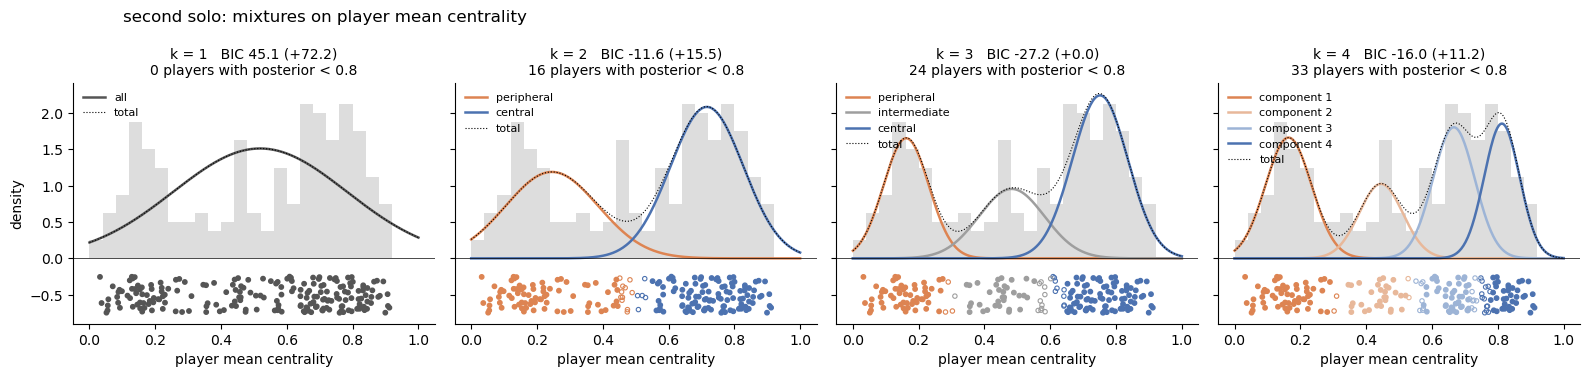

,session_type,bic,means,sds,weights
k,,,,,
1,solo2,45.069767790,[0.519],[0.264],[1.0]
2,solo2,-11.624615950,"[0.245, 0.717]","[0.141, 0.111]","[0.42, 0.58]"
3,solo2,-27.160296214,"[0.162, 0.483, 0.751]","[0.069, 0.1, 0.085]","[0.29, 0.24, 0.48]"
4,solo2,-15.960032899,"[0.164, 0.445, 0.667, 0.813]","[0.07, 0.067, 0.064, 0.054]","[0.29, 0.17, 0.29, 0.25]"


In [21]:
for st in ('solo1', 'solo2'):
    plot_fixed_cut(st)
    plot_mixtures(st)

**Interpretation**

- **First solo.** 100 central, 67 mixed and 33 peripheral players. Means form a large central peak near 0.7 and a smaller spread below 0.4. BIC clearly prefers 2 components (8 points ahead of 3).
- **Second solo.** 87 central, 55 mixed and 58 peripheral players. A distinct peripheral peak near 0.15 has appeared, and BIC prefers 3 components (11 points ahead of 4).
- Peripheral players nearly double between the solos, while central players fall by 13.

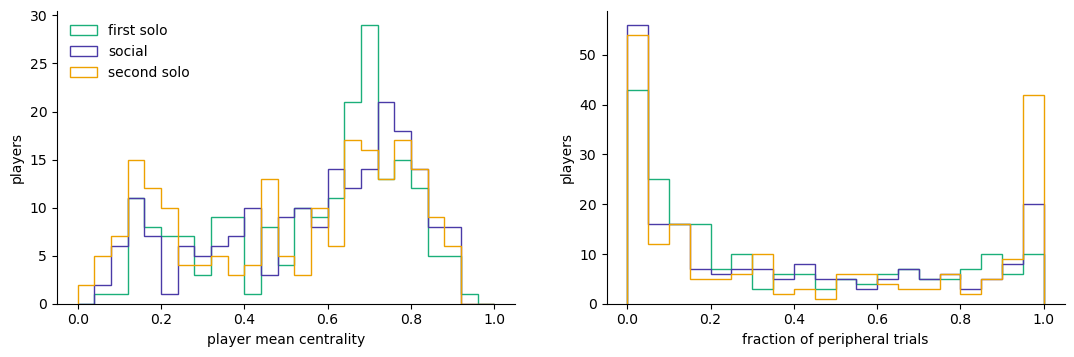

fixed                     gmm2               gmm3                        
             central mixed peripheral central peripheral central intermediate peripheral
session_type                                                                            
solo1            100    67         33     137         63     124           41         35
social            95    69         36     136         64      95           66         39
solo2             87    55         58     114         86      97           45         58

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for st in hc.SESSION_TYPES:
    sub = players[players['session_type'] == st]
    axes[0].hist(sub['mean_centrality'], bins=np.linspace(0, 1, 26), histtype='step', lw=1.8,
                 color=hc.SESSION_PALETTE[st], label=LABELS[st])
    axes[1].hist(sub['frac_peripheral'], bins=np.linspace(0, 1, 21), histtype='step', lw=1.8,
                 color=hc.SESSION_PALETTE[st], label=LABELS[st])
axes[0].set_xlabel('player mean centrality')
axes[1].set_xlabel('fraction of peripheral trials')
for ax in axes:
    ax.set_ylabel('players')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(frameon=False)
plt.show()

# count players per label in each session type
pd.concat({lab: players.groupby('session_type')[lab].value_counts().unstack(fill_value=0)
           for lab in ('fixed', 'gmm2', 'gmm3')}, axis=1).loc[list(hc.SESSION_TYPES)]

**Interpretation**

- All three sessions share the same broad shape, with a central peak and a wall peak.
- Between the solos, weight moves from the central peak (tall and narrow near 0.7 in the first solo) toward the wall. The second solo has the most players with nearly all trials peripheral.
- Social sits between the two solos on most counts. The shift toward the wall is clearest under gmm2 (63 to 64 to 86 peripheral players).

## 6. Change across sessions

### 6a. Each player's path

Each player has three values, one per session, so a line per player shows their path. Players are grouped by their first-solo label, so each panel starts from one strategy and shows where those players go. Thin lines are players and thick lines are the group mean.

The table below gives the mean change into social, and the change still present in the second solo.

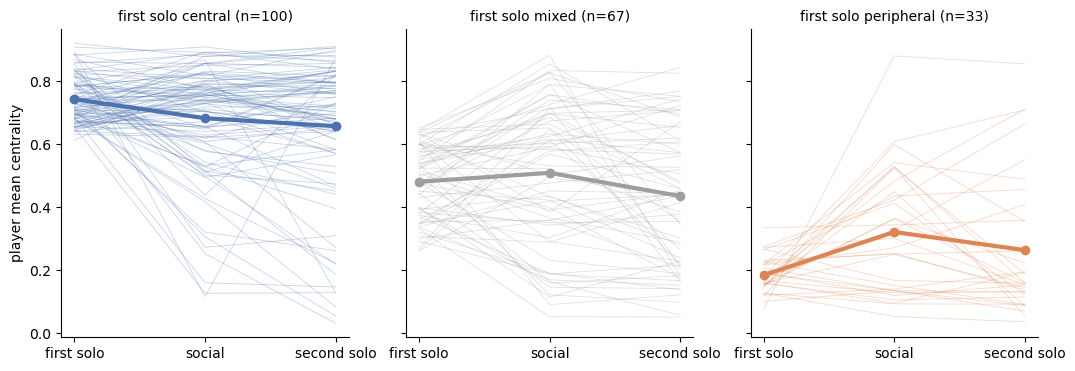

into_social             persistence             social_to_solo2            
                  mean    sem size        mean    sem size            mean    sem size
group                                                                                 
central         -0.060  0.018  100      -0.085  0.022  100          -0.025  0.015  100
mixed            0.028  0.025   67      -0.046  0.026   67          -0.074  0.022   67
peripheral       0.137  0.037   33       0.079  0.039   33          -0.057  0.030   33

In [23]:
wide = hc.wide_table(players)
labels_wide = hc.wide_table(players, WORKING_LABEL)
groups = labels_wide['solo1'].dropna()
groups = groups[groups != 'unassigned']

group_order = [g for g in label_order() if g in set(groups)]
fig, axes = plt.subplots(1, len(group_order), figsize=(4.2 * len(group_order), 4), sharey=True)
x = np.arange(len(hc.SESSION_TYPES))
for ax, g in zip(np.atleast_1d(axes), group_order):
    sub = wide.loc[groups.index[groups == g]]
    colour = label_colour(g)
    ax.plot(x, sub.T.to_numpy(), color=colour, lw=0.6, alpha=0.3)
    ax.plot(x, sub.mean().to_numpy(), color=colour, lw=3, marker='o')
    ax.set_xticks(x)
    ax.set_xticklabels([LABELS[st] for st in hc.SESSION_TYPES])
    ax.set_title(f'first solo {g} (n={len(sub)})', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)
np.atleast_1d(axes)[0].set_ylabel('player mean centrality')
plt.show()

# get mean change into social and from first to second solo, per group
change = pd.DataFrame(dict(group=groups, into_social=wide['social'] - wide['solo1'],
                           persistence=wide['solo2'] - wide['solo1'], social_to_solo2=wide['solo2'] - wide['social']))
change.groupby('group')[['into_social', 'persistence', 'social_to_solo2']].agg(['mean', 'sem', 'size']).round(3)

**Interpretation**

- Players who started central move toward the wall on average (0.75 to 0.68 to 0.66). Most change little, but a minority drop sharply, some below 0.3.
- Players who started peripheral move toward the centre in social (0.18 to 0.32) and keep part of it in the second solo (0.26).
- Mixed players change little into social and move toward the wall afterwards.
- Every group moves toward the wall from social to the second solo (−0.03 to −0.07).
- Part of the movement of the central and peripheral groups toward the middle is built in, because players were grouped on their first-solo value (6f step 3).

### 6b. Label transitions

The same paths as counts. Rows are the label a player held in the earlier session and columns the label they held in the later one, so the diagonal is players who kept their strategy. Row proportions divide by the row total, which is the share of each starting group that ended in each label.

A label change hides its own size. Moving from mixed to central can be a large shift or a small one that happened to cross a cut, and the two mean different things. The second table gives each cell the movement behind it: `median_change` in mean centrality, signed toward the centre, and `share_marginal`, the fraction of players in that cell whose values sat within 0.1 of a cut in **both** sessions, where the label change rests on a hair's breadth.

In [24]:
for a, b in (('solo1', 'social'), ('social', 'solo2'), ('solo1', 'solo2')):
    tab = hc.transition_table(players, WORKING_LABEL, a, b)
    print(f"{LABELS[a]} (rows) to {LABELS[b]} (columns)")
    display(pd.concat({'count': tab, 'row proportion': tab.div(tab.sum(axis=1), axis=0).round(2)}, axis=1))

# show how far the players in each cell actually moved
print('size of the move behind each transition')
display(hc.transition_detail(players, WORKING_LABEL, 'solo1', 'social').round(3))

first solo (rows) to social (columns)


count                  row proportion                 
social     central mixed peripheral        central mixed peripheral
solo1                                                              
central         71    25          4           0.71  0.25       0.04
mixed           23    29         15           0.34  0.43       0.22
peripheral       1    15         17           0.03  0.45       0.52

social (rows) to second solo (columns)


count                  row proportion                 
solo2      central mixed peripheral        central mixed peripheral
social                                                             
central         74    17          4           0.78  0.18       0.04
mixed           12    34         23           0.17  0.49       0.33
peripheral       1     4         31           0.03  0.11       0.86

first solo (rows) to second solo (columns)


count                  row proportion                 
solo2      central mixed peripheral        central mixed peripheral
solo1                                                              
central         68    21         11           0.68  0.21       0.11
mixed           15    29         23           0.22  0.43       0.34
peripheral       4     5         24           0.12  0.15       0.73

size of the move behind each transition


n  median_change  median_abs_change  share_marginal
solo1      social                                                          
central    central     71          0.026              0.049           0.113
           mixed       25         -0.254              0.254           0.200
           peripheral   4         -0.554              0.554           0.000
mixed      central     23          0.212              0.212           0.217
           mixed       29          0.015              0.072           0.172
           peripheral  15         -0.237              0.237           0.133
peripheral central      1          0.803              0.803           0.000
           mixed       15          0.297              0.297           0.133
           peripheral  17         -0.039              0.054           0.059

**Interpretation**

- Players keep their label more often from social to the second solo (139 of 200) than from the first solo to social (117) or between the two solos (121).
- Social peripheral players are the most stable, as 86% stay peripheral in the second solo. First-solo peripheral players are the least stable into social, with 45% becoming mixed.
- Label changes mostly reflect real moves. The median shift behind every changed label is at least 0.21, and at most 22% of the players in those cells sat near a cut in both sessions.
- Between the solos, moves to the wall outnumber moves to the centre (11 central players become peripheral, 4 go the other way).

### 6c. Does the social change persist?

Second-solo centrality is regressed on first-solo and social centrality together. The two predictors are correlated, so each coefficient is what that session adds once the other is known. A social coefficient above zero means where a player stood in the social session predicts their second solo beyond what their first solo already predicted, which is what a lasting change looks like.

**Reading the table.** All three columns are centrality, so the coefficients are directly comparable. `coef` is how much second-solo centrality moves per 1 unit of a predictor, holding the other fixed, and since centrality only spans 0 to 1, a coefficient near 1 means the predictor carries over almost completely. `std err` is the uncertainty on that estimate and `t` is the coefficient divided by it, so `P>|t|` tests the coefficient against zero and `[0.025 0.975]` gives the range the data leave open. The intercept is where the line sits when both predictors are 0, which is outside the range players occupy and so is not worth interpreting. `R²` is the share of the spread in second-solo centrality the two predictors together account for.

Two cautions. The predictors correlate at 0.59, which widens both standard errors and makes the split between the two coefficients less certain than either alone. And this is prediction, not cause: a player's social session may carry over, or both sessions may reflect something stable in the player that the first solo measured imperfectly.

No group played two solos without a social session in between, so this cannot separate a social effect from practice on its own. The timeline in 6e is the check on that.

In [25]:
print(wide.corr().round(3))
fit = hc.persistence_model(wide)
print(f"\nn = {int(fit.nobs)}, R² = {fit.rsquared:.3f}")
print(fit.summary().tables[1])

session_type  solo1  social  solo2
session_type                      
solo1         1.000   0.594  0.589
social        0.594   1.000  0.787
solo2         0.589   0.787  1.000

n = 200, R² = 0.643
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0339      0.033     -1.027      0.306      -0.099       0.031
solo1          0.2220      0.063      3.545      0.000       0.099       0.345
social         0.7558      0.059     12.766      0.000       0.639       0.873


**Interpretation**

- Social position predicts the second solo far better than the first solo does (r = 0.79 against 0.59). With both in the model, the social coefficient is 0.76 and the first-solo coefficient 0.22.
- Where a player stood in social carries over strongly once they play alone again.
- This does not show that social caused it. Social sits between the two solos in time, so any gradual change in a player would also make social the better predictor.
- Standard errors here are not clustered by experiment, unlike 6f, so they are somewhat too narrow.

### 6d. Partner influence

Does a player's later position follow where their partner started?

**Data.** One row per player (200). Each row holds three mean onset centralities (0 = alcove back, 1 = centre).
- `own_solo`, the player's first solo
- `partner_solo`, the partner's first solo
- `social`, the player's social session (top row). The bottom row uses the player's second solo in its place.

**Model.** `social = a + b × own_solo + c × partner_solo`

The fit is ordinary least squares, the same method as a line of best fit but with two predictors. It picks a, b and c to minimise the summed squared gap between predicted and actual `social`, and has a direct solution rather than an iterative search. Standard errors are clustered by experiment, as partners are not independent. This widens the confidence interval but does not change a, b or c.

**c is the partner effect.** It is how much more central a player sits in social for each unit their partner started more central, with `own_solo` held fixed. c = 0 means no partner effect.

**Why this design.** An earlier version plotted change (`social − own_solo`) against gap (`partner_solo − own_solo`). Both axes subtracted `own_solo`, which built a positive slope into the plot whatever players did. The model here holds `own_solo` fixed instead, so c can be read at face value.

**What the overlap is.** Across the 200 players, `partner_solo` tends to be slightly higher when `own_solo` is higher (r = 0.17). A line through the (`own_solo`, `partner_solo`) points has slope 0.168. Partners do not play together before social, so this is not an interaction and nothing here predicts one player from the other in a causal sense. It is a statistical overlap, from chance or from something the two players shared on the day. Section 3d shows it is larger than random pairings give (p = 0.016).

**Why the overlap needs removing.**
- With the overlap, `partner_solo` carries a little information about `own_solo`. A player with a central partner is slightly more likely to be central themselves.
- `own_solo` strongly predicts `social`. So a slope of `social` on raw `partner_solo` would partly credit the partner for the player's own start. That raw slope is 0.34, against c = 0.24, so about 0.10 of it arrives through `own_solo`.
- Removing the overlap keeps only the part of `partner_solo` unrelated to `own_solo`. If partners were truly unrelated, the overlap slope would be 0 and nothing would be removed.
- Plotting y against raw `partner_solo` would give a slope of c × (1 − r²), 0.229 here against c = 0.236. The overlap is removed so that the drawn slope equals c exactly.

**How the left panels are built.** Each point is one player. Its two values come from two straight lines, each fitted across all 200 players (the average first solo is 0.564).
1. **y removes what `own_solo` predicts from `social`.** A line through (`own_solo`, `social`) gives `expected social = 0.212 + 0.628 × own_solo`. Then **y = social − expected social**, how much more central the player sat in social than their own start predicts.
2. **x removes the overlap from `partner_solo`.** A line through (`own_solo`, `partner_solo`) gives `0.469 + 0.168 × own_solo`, which is the same as `0.564 + 0.168 × (own_solo − 0.564)`. The first term is the average `partner_solo`. The second is the overlap part, the shift in `partner_solo` that goes with this player's own start. Then **x = (partner_solo − 0.564) − overlap part**, how far the partner started from the average partner, beyond anything shared with this player's start.

Both x and y are centrality differences, so they can be negative. y = 0 means the player sat exactly where their own start predicts, and x = 0 means the partner started at the average once the overlap is removed.

**Worked example (the two players of experiment 0).**

| | own_solo | partner_solo | social | expected social | y | partner_solo − 0.564 | overlap part, 0.168 × (own_solo − 0.564) | x |
|---|---|---|---|---|---|---|---|---|
| player 0 | 0.180 | 0.795 | 0.609 | 0.212 + 0.628 × 0.180 = 0.324 | +0.28 | +0.231 | −0.065 | 0.231 − (−0.065) = +0.30 |
| player 1 | 0.795 | 0.180 | 0.736 | 0.212 + 0.628 × 0.795 = 0.711 | +0.02 | −0.384 | +0.039 | −0.384 − 0.039 = −0.42 |

Player 0 started near the wall but sat much more central in social than that predicts (y = +0.28), and their partner started well above the average partner (x = +0.30). Player 1 sat about where their own start predicts (y = +0.02), and their partner started well below the average partner (x = −0.42). The overlap parts are small (under 0.07), as partners are only slightly alike. The first figure below draws these steps for both players.

**Reading the slope.** A line fitted to the (x, y) points has slope exactly c (the Frisch–Waugh–Lovell theorem), so the drawn line is c from the full model. It passes through 0 because x and y each average 0.

**Rows.** Both rows use the same players and the same x values. Only the y side changes.
- **Top row, social.** Does `partner_solo` predict where the player waits while they play together?
- **Bottom row, second solo.** The second solo replaces `social` in step 1. Does `partner_solo` still predict where the player waits once they play alone again? A c above 0 here means the partner effect outlasts the shared session.

**Right panels.** Each of 2000 draws gives every player a stand-in `partner_solo` (the first solo of a player from another experiment) and refits c. The bars are those values, and they centre on 0. p (random partners) is the share of draws at or above the real c.

The table repeats the fit on 2026 experiments only, where every session ran the same protocol.

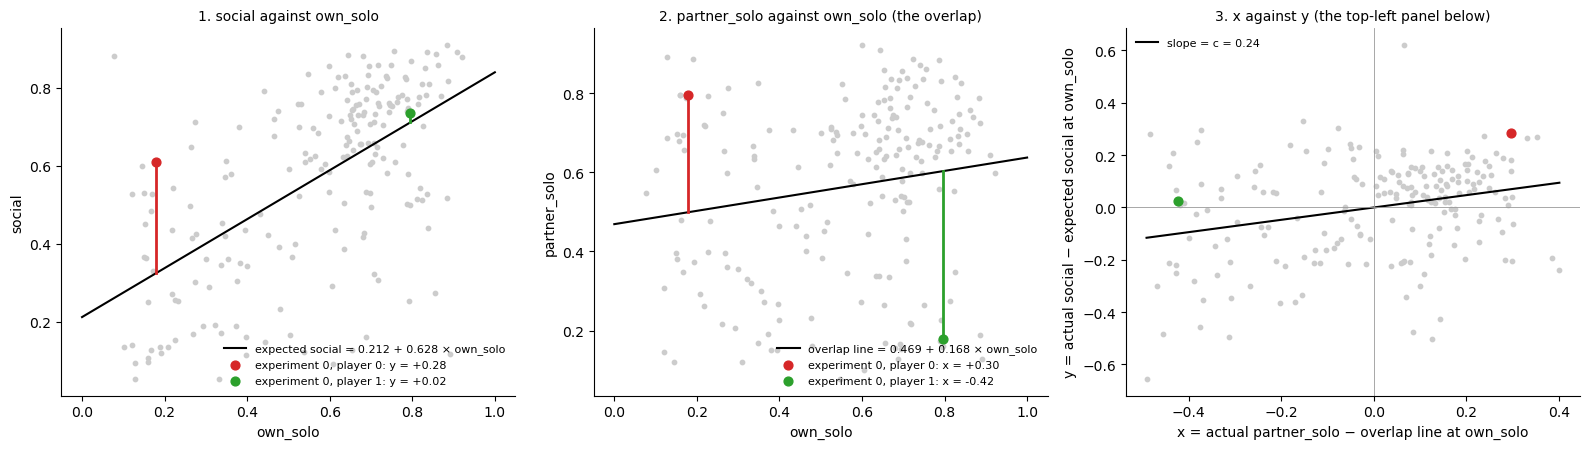

In [26]:
# get own_solo, partner_solo and social for every player
steps = wide[['solo1', 'social']].rename(columns={'solo1': 'own_solo'})
steps['partner_solo'] = wide['solo1'].reindex([(e, 1 - p) for e, p in wide.index]).to_numpy()
steps = steps.dropna()

# fit the line for y (social on own_solo) and the overlap line (partner_solo on own_solo), and take each player's vertical gap from them
b_y, a_y = np.polyfit(steps['own_solo'], steps['social'], 1)
b_x, a_x = np.polyfit(steps['own_solo'], steps['partner_solo'], 1)
steps['y'] = steps['social'] - (a_y + b_y * steps['own_solo'])
steps['x'] = steps['partner_solo'] - (a_x + b_x * steps['own_solo'])

example = {(0, 0): '#d62728', (0, 1): '#2ca02c'}
line_x = np.array([0, 1])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, col, a, b, gap, title, name in (
        (axes[0], 'social', a_y, b_y, 'y', '1. social against own_solo', 'expected social'),
        (axes[1], 'partner_solo', a_x, b_x, 'x', '2. partner_solo against own_solo (the overlap)', 'overlap line')):
    # plot every player and the fitted line
    ax.scatter(steps['own_solo'], steps[col], s=10, color='#cccccc')
    ax.plot(line_x, a + b * line_x, color='k', lw=1.5, label=f'{name} = {a:.3f} + {b:.3f} × own_solo')
    # draw each example player's vertical gap from the line
    for key, colour in example.items():
        r = steps.loc[key]
        ax.plot([r['own_solo']] * 2, [a + b * r['own_solo'], r[col]], color=colour, lw=2)
        ax.scatter(r['own_solo'], r[col], s=40, color=colour, zorder=3,
                   label=f'experiment {key[0]}, player {key[1]}: {gap} = {r[gap]:+.2f}')
    ax.set_xlabel('own_solo')
    ax.set_ylabel(col)
    ax.set_title(title, fontsize=10)
    ax.legend(frameon=False, fontsize=8, loc='lower right')

# plot the gaps against each other, one point per player
ax = axes[2]
ax.scatter(steps['x'], steps['y'], s=10, color='#cccccc')
slope = np.polyfit(steps['x'], steps['y'], 1)[0]
gap_x = np.array([steps['x'].min(), steps['x'].max()])
ax.plot(gap_x, slope * gap_x, color='k', lw=1.5, label=f'slope = c = {slope:.2f}')
for key, colour in example.items():
    r = steps.loc[key]
    ax.scatter(r['x'], r['y'], s=40, color=colour, zorder=3)
ax.axhline(0, color='#999999', lw=0.6)
ax.axvline(0, color='#999999', lw=0.6)
ax.set_xlabel('x = actual partner_solo − overlap line at own_solo')
ax.set_ylabel('y = actual social − expected social at own_solo')
ax.set_title('3. x against y (the top-left panel below)', fontsize=10)
ax.legend(frameon=False, fontsize=8, loc='upper left')
for a in axes:
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


#### Where the values come from, and how y is built (player 0 of experiment 0)

Every value in the model is a session mean of onset centrality, one value per trial averaged over the session.
- `own_solo` is the mean over player 0's first-solo trials (after the 5-trial cut).
- `social` is the mean over player 0's social trials.
- `partner_solo` is the mean over player 1's first-solo trials.

Player 1's social mean is not used for player 0. It only enters when player 1 is the player.

The second figure zooms in on step 1 for player 0. Its horizontal axis is `own_solo` and its vertical axis is `social`. The line gives the social value typical for a player with that first solo. y is the vertical gap between player 0's actual `social` and the line.

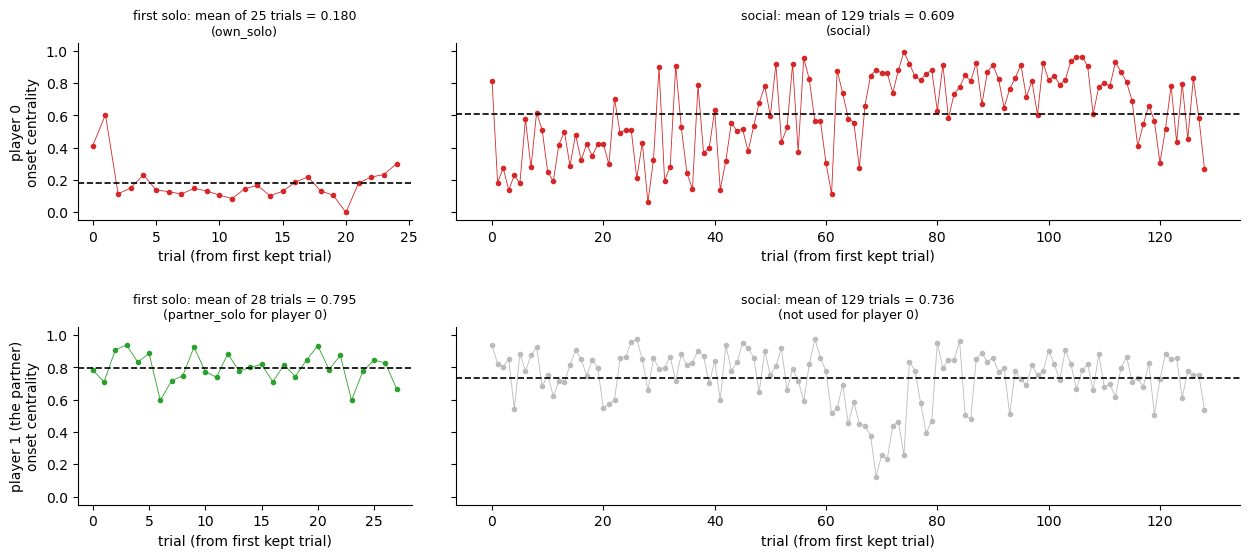

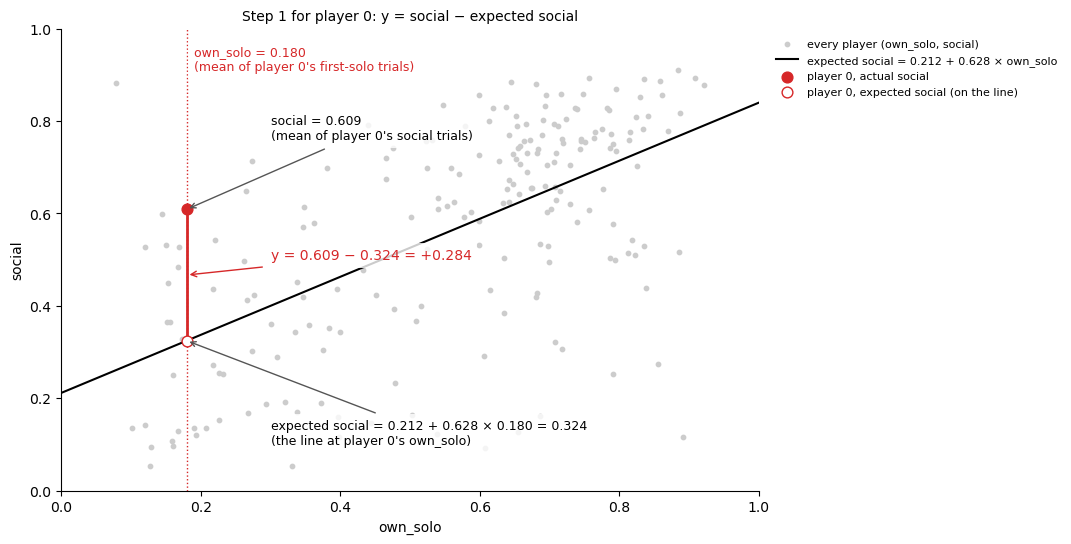

In [27]:
# get the trials of both players of experiment 0 in their first solo and social sessions
ex_trials = onset[onset['experiment'] == 0]
n_solo = ex_trials.loc[ex_trials['session_type'] == 'solo1', 'trial_pos'].max() + 1
n_social = ex_trials.loc[ex_trials['session_type'] == 'social', 'trial_pos'].max() + 1
fig, axes = plt.subplots(2, 2, figsize=(15, 6), sharey=True,
                         gridspec_kw=dict(width_ratios=[max(n_solo, 55), n_social], hspace=0.6, wspace=0.08))
panels = {(0, 'solo1'): ('first solo', 'own_solo', '#d62728'),
          (0, 'social'): ('social', 'social', '#d62728'),
          (1, 'solo1'): ('first solo', 'partner_solo for player 0', '#2ca02c'),
          (1, 'social'): ('social', 'not used for player 0', '#bbbbbb')}
for (player, st), (title, name, colour) in panels.items():
    ax = axes[player, 0 if st == 'solo1' else 1]
    sub = ex_trials[(ex_trials['player'] == player) & (ex_trials['session_type'] == st)].sort_values('trial_pos')
    # plot every trial's onset centrality and the session mean
    ax.plot(sub['trial_pos'], sub['centrality'], 'o-', ms=3, lw=0.6, color=colour)
    ax.axhline(sub['centrality'].mean(), color='k', ls='--', lw=1.2)
    ax.set_title(f"{title}: mean of {len(sub)} trials = {sub['centrality'].mean():.3f}\n({name})", fontsize=9)
    ax.set_xlabel('trial (from first kept trial)')
    ax.set_ylim(-0.05, 1.05)
    ax.spines[['top', 'right']].set_visible(False)
axes[0, 0].set_ylabel('player 0\nonset centrality')
axes[1, 0].set_ylabel('player 1 (the partner)\nonset centrality')
plt.show()

# plot step 1 for player 0, labelling every value behind y
r = steps.loc[(0, 0)]
expected = a_y + b_y * r['own_solo']
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(steps['own_solo'], steps['social'], s=10, color='#cccccc', label='every player (own_solo, social)')
ax.plot(line_x, a_y + b_y * line_x, color='k', lw=1.5, label=f'expected social = {a_y:.3f} + {b_y:.3f} × own_solo')
ax.axvline(r['own_solo'], color='#d62728', ls=':', lw=1)
ax.plot([r['own_solo']] * 2, [expected, r['social']], color='#d62728', lw=2)
ax.scatter(r['own_solo'], r['social'], s=60, color='#d62728', zorder=3, label='player 0, actual social')
ax.scatter(r['own_solo'], expected, s=60, facecolor='white', edgecolor='#d62728', zorder=3,
           label='player 0, expected social (on the line)')
arrow = dict(arrowstyle='->', color='#555555')
ax.annotate(f"social = {r['social']:.3f}\n(mean of player 0's social trials)", xy=(r['own_solo'], r['social']),
            xytext=(0.30, 0.76), fontsize=9, arrowprops=arrow,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.annotate(f"expected social = {a_y:.3f} + {b_y:.3f} × {r['own_solo']:.3f} = {expected:.3f}\n(the line at player 0's own_solo)",
            xy=(r['own_solo'], expected), xytext=(0.30, 0.10), fontsize=9, arrowprops=arrow,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.annotate(f"y = {r['social']:.3f} − {expected:.3f} = {r['y']:+.3f}", xy=(r['own_solo'], (expected + r['social']) / 2),
            xytext=(0.30, 0.50), fontsize=10, color='#d62728', arrowprops=dict(arrowstyle='->', color='#d62728'),
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.annotate(f"own_solo = {r['own_solo']:.3f}\n(mean of player 0's first-solo trials)", xy=(r['own_solo'], 0.97),
            xytext=(r['own_solo'] + 0.01, 0.91), fontsize=9, color='#d62728',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.8))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel('own_solo')
ax.set_ylabel('social')
ax.set_title('Step 1 for player 0: y = social − expected social', fontsize=10)
ax.legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.spines[['top', 'right']].set_visible(False)
plt.show()


human_partner_influence: loaded from cache


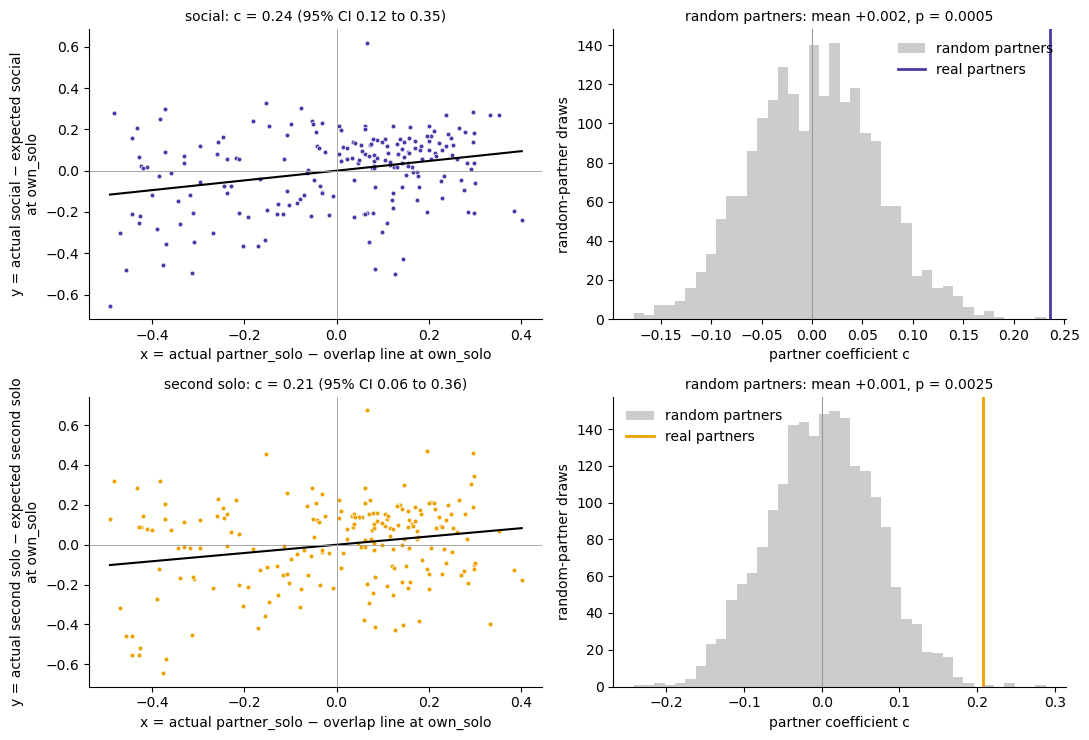

players       c   ci_lo   ci_hi       p  p_random_partners  b_own_solo
subset          session                                                                            
all experiments social           200  0.2357  0.1214  0.3500  0.0001             0.0005      0.5885
                second solo      200  0.2074  0.0587  0.3561  0.0063             0.0025      0.6619
2026 only       social            64  0.2484  0.0315  0.4652  0.0248             0.0070      0.6760
                second solo       64  0.4317  0.2494  0.6140  0.0000             0.0005      0.5999

In [28]:
# fit social (or second solo) ~ own_solo + partner_solo, for every experiment and for 2026 only
recent = set(experiments.loc[experiments['date'].dt.year == 2026, 'experiment'])
wide_recent = wide[wide.index.get_level_values('experiment').isin(recent)]
subsets = {'all experiments': wide, '2026 only': wide_recent}
influence = data_saving.cached(
    'human_partner_influence',
    lambda: {(name, t): hc.partner_influence(w, target=t, n_perm=N_PERM)
             for name, w in subsets.items() for t in ('social', 'solo2')},
    recompute=RECOMPUTE, stamp=dict(n_perm=N_PERM, wide=float(wide.sum().sum()), n_recent=len(wide_recent)))

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for row, target in enumerate(('social', 'solo2')):
    res = influence[('all experiments', target)]
    # plot y (actual minus expected later value) against x (actual partner_solo minus the overlap line)
    ax = axes[row, 0]
    ax.scatter(res['x_resid'], res['y_resid'], s=12, color=hc.SESSION_PALETTE[target], edgecolor='white', linewidth=0.5)
    xx = np.array([res['x_resid'].min(), res['x_resid'].max()])
    ax.plot(xx, res['coef'] * xx, color='k', lw=1.5)
    ax.axhline(0, color='#999999', lw=0.6)
    ax.axvline(0, color='#999999', lw=0.6)
    ax.set_title(f"{LABELS[target]}: c = {res['coef']:.2f} (95% CI {res['ci_lo']:.2f} to {res['ci_hi']:.2f})",
                 fontsize=10)
    ax.set_xlabel('x = actual partner_solo − overlap line at own_solo')
    later = 'social' if target == 'social' else 'second solo'
    ax.set_ylabel(f'y = actual {later} − expected {later}\nat own_solo')

    # plot c for random stand-in partner_solo values, with the real c
    ax = axes[row, 1]
    ax.hist(res['null'], bins=40, color='#cccccc', label='random partners')
    ax.axvline(0, color='#999999', lw=0.8)
    ax.axvline(res['coef'], color=hc.SESSION_PALETTE[target], lw=2, label='real partners')
    ax.set_title(f"random partners: mean {res['null'].mean():+.3f}, p = {res['p_random']:.3g}", fontsize=10)
    ax.set_xlabel('partner coefficient c')
    ax.set_ylabel('random-partner draws')
    ax.legend(frameon=False)
for ax in axes.ravel():
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

# summarise c for every experiment and for 2026 only
pd.DataFrame([dict(subset=name, session=LABELS[t], players=r['n'], c=r['coef'], ci_lo=r['ci_lo'], ci_hi=r['ci_hi'],
                   p=r['p'], p_random_partners=r['p_random'], b_own_solo=r['own_coef'])
              for (name, t), r in influence.items()]).set_index(['subset', 'session']).round(4)


**Interpretation**

- **partner_solo predicts where a player waits in social.** A partner_solo 0.1 higher goes with the player sitting 0.024 more central in social (c = 0.24, 95% CI 0.12 to 0.35), beyond what own_solo predicts.
- **The effect lasts into the second solo** (c = 0.21, 95% CI 0.06 to 0.36), when partners no longer play together.
- **Random partners give c near 0**, and the real c sits above all but a few draws (p = 0.0005 and 0.0025). This confirms the plot has no built-in slope.
- **2026 experiments alone show the same** (c = 0.25 in social and 0.43 in the second solo, 32 pairs), so the effect does not come from mixing protocols.
- **own_solo still matters most** (b = 0.59 in social and 0.66 in the second solo, against c = 0.21 to 0.24).
- **Two cautions.** Partners are already a little alike in their first solos (3d). The model holds own_solo fixed, but anything shared on the day that shaped both partners' later sessions, and not their first solos, would also show up in c. c also does not say how the effect arises (e.g. copying, learning from losses, or reacting to the partner's position).

### 6e. Timeline

Mean onset centrality in bins of 10 trials, plotted across the three sessions and grouped by first-solo label. Each player is averaged within a bin first, so players with more trials do not dominate a bin. Bands are the standard error across players, and bins holding fewer than 5 players are dropped.

This separates a step at the social session from a trend that was already running. Drift inside the first solo, continuing through social and into the second solo, points to practice rather than to the social session. The first-solo panel is partly circular, because the groups are defined from those same trials.

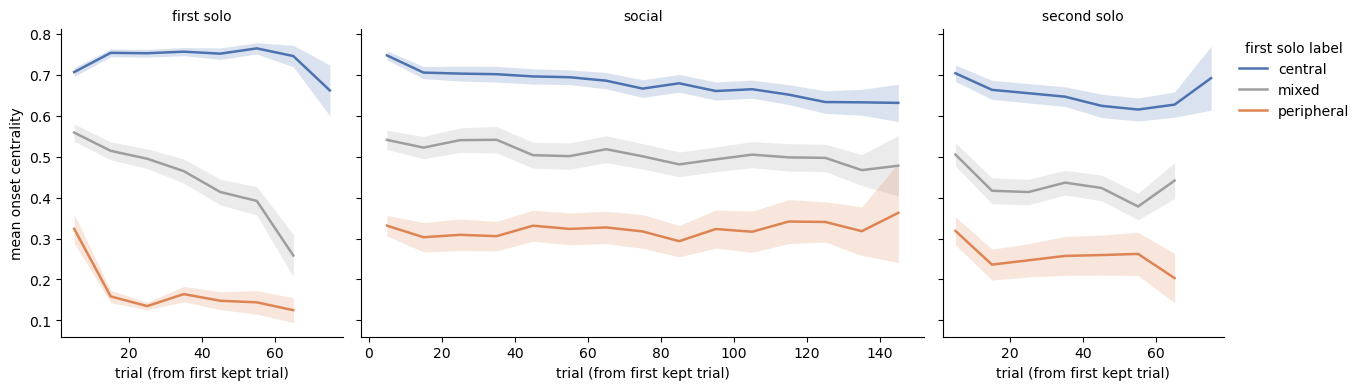

In [29]:
tl = hc.binned_timeline(onset, groups, bin_size=BIN_SIZE)
n_bins = tl.groupby('session_type', observed=True)['bin'].max() + 1
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True,
                         gridspec_kw=dict(width_ratios=[n_bins[st] for st in hc.SESSION_TYPES], wspace=0.05))
for ax, st in zip(axes, hc.SESSION_TYPES):
    for g in group_order:
        s = tl[(tl['session_type'] == st) & (tl['group'] == g) & (tl['n'] >= 5)]
        centre = (s['bin'] + 0.5) * BIN_SIZE
        colour = label_colour(g)
        ax.fill_between(centre, s['mean'] - s['sem'], s['mean'] + s['sem'], color=colour, alpha=0.2, lw=0)
        ax.plot(centre, s['mean'], color=colour, lw=1.8, label=g)
    ax.set_title(LABELS[st], fontsize=10)
    ax.set_xlabel('trial (from first kept trial)')
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('mean onset centrality')
axes[-1].legend(title='first solo label', frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.show()

**Interpretation**

- The three groups stay apart through all three sessions.
- **First solo.** The mixed group falls steadily toward the wall (0.56 to 0.26). This is partly circular, since the groups come from these trials, but it matches the switchers in 4c.
- **Social.** The peripheral group starts at 0.33, well above where it ended the first solo (about 0.13), and stays there. A slow practice trend would not produce that jump. The central group slides slowly toward the wall (0.75 to 0.63).
- **Second solo.** Every group starts more central, drops over the first 10 to 20 trials, then levels off.
- The central group's slide toward the wall runs through all three sessions, which fits practice as well as a social effect.

### 6f. First solo to second solo

This is the cleanest comparison in the data. Both sessions are the same task in the same context, played alone, so a difference between them is not tangled up with the presence of an opponent at the time of measuring. What sits between them is the social session and more time on the task. Every player took the sessions in the same order and no one played two solos without a social session in between, so those two cannot be separated by design. Step 4 separates them as far as the data allow.

Positions are logged exactly, so no step here corrects for measurement error. Where an interval appears, it asks whether a player would show a similar result over a **different set of trials**, which matters because a session mean is built from a limited number of trials of a player who varies from one trial to the next.

The steps:
1. How stable is a player's position between the two solos, against how consistent each solo is with itself?
2. Did players move on average, overall and by first-solo label?
3. Do players who started at an extreme end nearer the middle?
4. Does the second solo follow the social session, or a drift already running in the first solo?
5. Which individual players changed most.

#### 1. How stable is the position?

Stability is the correlation between a player's first-solo and second-solo means. On its own that number is hard to read, as a limited number of trials would keep it below 1 even for players who never changed. Consistency sets the ceiling. It is the odd-even split-half reliability of each solo, corrected to full length, and says how well a session agrees with itself. Dividing the stability by the ceiling gives the stability players would show with unlimited trials.

A corrected value near 1 would mean waiting position is a fixed habit. A value well below 1 means players genuinely behave differently between the two solos.

In [30]:
ceiling = hc.stability_ceiling(onset, players, 'solo1', 'solo2')
ceiling.round(3).to_frame('first solo to second solo')

,first solo to second solo
between_sessions_r,0.589
consistency_solo1,0.990
consistency_solo2,0.996
ceiling,0.993
corrected_r,0.593
n_players,200.000


**Interpretation**

- A player's first-solo mean predicts their second-solo mean only moderately (r = 0.59).
- Each solo agrees closely with itself (0.99), so the ceiling is near 1 and the corrected value barely changes (0.59).
- Players genuinely change their waiting position between the two solos. The limited number of trials does not explain the gap.

#### 2. Did players move on average?

The mean of each player's change, second solo minus first solo, overall and split by the label they held in the first solo. Partners share a social session, so their changes are linked. The standard error is clustered by experiment, which treats the two players of an experiment as one source of evidence rather than two.

Groups use `WORKING_LABEL`. A group change is partly built in by the grouping itself, because players were placed in a group by their first-solo value, so group means will tend toward the overall mean in the second solo. Step 3 handles that properly, and the group rows here are best read as a description.

In [31]:
hc.paired_change(players, 'solo1', 'solo2', group_col=WORKING_LABEL).round(3)

,n,mean_change,se,ci_lo,ci_hi,p
group,,,,,,
all,200,-0.045,0.017,-0.078,-0.012,0.008
central,100,-0.085,0.023,-0.130,-0.041,0.000
mixed,67,-0.046,0.027,-0.099,0.008,0.096
peripheral,33,0.079,0.039,0.002,0.156,0.044


**Interpretation**

- On average, players move toward the wall by 0.045 between the solos (95% CI −0.08 to −0.01).
- The move comes from first-solo central players (−0.085). Peripheral players move slightly toward the centre (+0.08, p = 0.044), and mixed players show no reliable move.
- The opposite signs of the central and peripheral groups are partly built in by the grouping (step 3).

#### 3. Do extremes move toward the middle, and who changed?

Plotting each player's change against their starting value looks natural but misleads. The starting value is subtracted inside the change, so any imperfect link between the two solos makes players who started high look like they fell and players who started low look like they rose, with no real tendency behind it. The left panel avoids this by plotting the second solo against the first, both as mean centrality.

- The dashed diagonal is no change. A point above it rose toward the centre, below it fell toward the wall.
- The solid line is the fitted relationship. A slope below 1 means players who started at an extreme ended the second solo nearer the middle.
- Each vertical bar is that player's interval on their second-solo value, from redrawing both solos' trials in overlapping blocks of 10. Blocks keep a player's runs of one strategy together. A steady player gets a short bar and a mixed player a long one.

The right panel lays out every player's change in order of size, with the same interval, so the full spread is visible without sorting players into movers and non-movers.

human_solo_change: loaded from cache


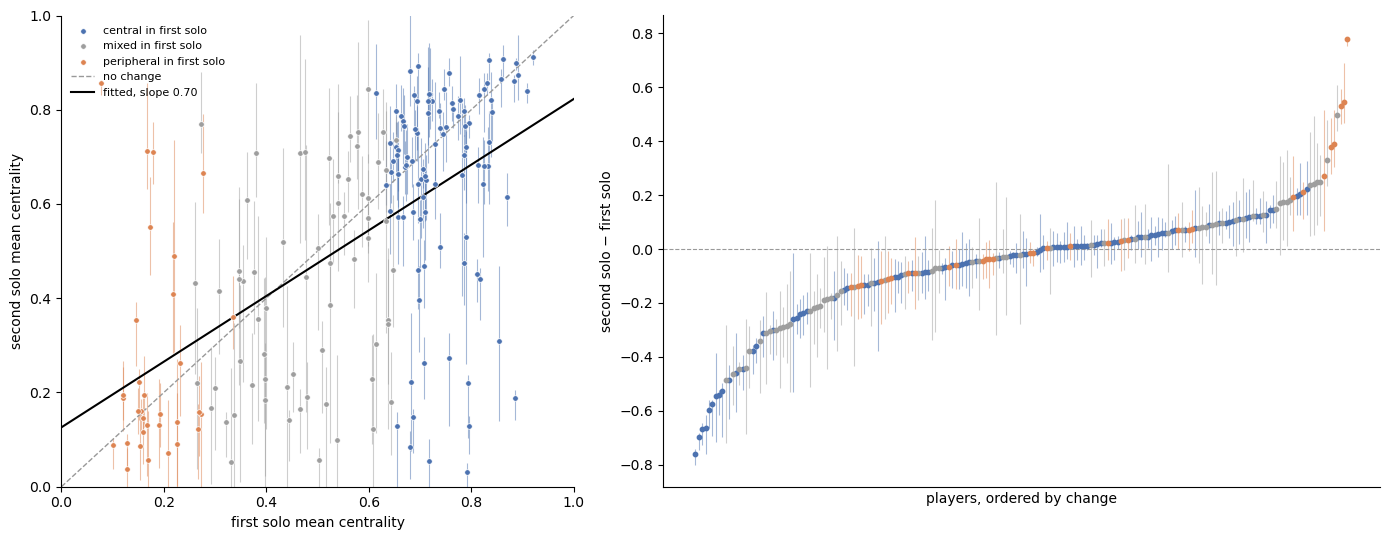

slope 0.697 (95% CI 0.559 to 0.835), n = 200, clustered by experiment
median interval width on a player's change: 0.152


In [32]:
solo_change = data_saving.cached(
    'human_solo_change', lambda: hc.player_change(onset, 'solo1', 'solo2', n_boot=N_PERM_DRIFT),
    recompute=RECOMPUTE, stamp=dict(n_boot=N_PERM_DRIFT, rows=len(onset)))
shrink = hc.shrinkage_model(wide, 'solo1', 'solo2')

# join each player's two solo means and first-solo label to their change
pts = (solo_change.set_index(['experiment', 'player'])
       .join(wide[['solo1', 'solo2']])
       .join(labels_wide['solo1'].rename('label')))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw=dict(width_ratios=[1, 1.4]))

# plot the second solo against the first, with each player's interval on the second
ax = axes[0]
for lab in WORKING_ORDER:
    sub = pts[pts['label'] == lab]
    ax.vlines(sub['solo1'], sub['solo1'] + sub['ci_lo'], sub['solo1'] + sub['ci_hi'],
              color=label_colour(lab), lw=0.8, alpha=0.5)
    ax.scatter(sub['solo1'], sub['solo2'], s=16, color=label_colour(lab), edgecolor='white', linewidth=0.5,
               label=f'{lab} in first solo', zorder=3)
xx = np.array([0, 1])
ax.plot(xx, xx, color='#999999', lw=1, ls='--', label='no change')
ax.plot(xx, shrink.params['Intercept'] + shrink.params['solo1'] * xx, color='k', lw=1.5,
        label=f"fitted, slope {shrink.params['solo1']:.2f}")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel('first solo mean centrality')
ax.set_ylabel('second solo mean centrality')
ax.legend(frameon=False, fontsize=8, loc='upper left')

# plot every player's change in order of size, with its interval
ax = axes[1]
order = pts.sort_values('change')
x = np.arange(len(order))
for lab in WORKING_ORDER:
    m = (order['label'] == lab).to_numpy()
    ax.vlines(x[m], order['ci_lo'][m], order['ci_hi'][m], color=label_colour(lab), lw=0.8, alpha=0.5)
    ax.scatter(x[m], order['change'][m], s=10, color=label_colour(lab), zorder=3)
ax.axhline(0, color='#999999', lw=0.8, ls='--')
ax.set_xticks([])
ax.set_xlabel('players, ordered by change')
ax.set_ylabel('second solo − first solo')
for a in axes:
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

lo, hi = shrink.conf_int().loc['solo1']
print(f"slope {shrink.params['solo1']:.3f} (95% CI {lo:.3f} to {hi:.3f}), n = {int(shrink.nobs)}, "
      f"clustered by experiment")
print(f"median interval width on a player's change: {(solo_change['ci_hi'] - solo_change['ci_lo']).median():.3f}")

**Interpretation**

- The fitted slope is 0.70 (95% CI 0.56 to 0.84), below 1. Players who started at an extreme tend to end the second solo nearer the middle.
- The scatter is lopsided. Most first-solo peripheral players stay near the wall, with a few jumping to the centre. A larger set of central players falls well below the diagonal, some to the wall.
- Large changes mostly go toward the wall (25 players moved more than 0.3 toward it, 7 toward the centre). Half of all players changed by less than 0.1.
- Intervals are narrow for steady players and wide for mixed ones (median width 0.15). Most large changes keep an interval clear of 0, so they would hold over a different set of trials.

#### 4. Social session or practice?

Two explanations for a second-solo change, tested in one model. Second-solo centrality is predicted from:

- **first solo**, so both other terms describe change beyond where a player started;
- **social**, the player's mean in the social session. If the social session changed players, this should predict their second solo once their first solo is known;
- **first-solo drift**, the slope of centrality across the first solo in centrality per 100 trials, from section 4b. If the change is just more time on the task, a player already drifting should keep going the same way.

A coefficient is how much second-solo centrality moves per unit of that predictor with the others held fixed. The drift term is on a different scale from the other two (a slope of 1 is a full unit of centrality per 100 trials, far beyond any player), so compare its p value with the others rather than its size. Both can be true at once. Standard errors are clustered by experiment. Players with fewer than 20 first-solo trials have no drift slope and drop out.

In [33]:
sp = hc.social_or_practice_model(wide, drift)
print(f"n = {int(sp.nobs)}, R² = {sp.rsquared:.3f}, clustered by experiment")
print(sp.summary().tables[1])

n = 194, R² = 0.653, clustered by experiment
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       0.0097      0.029      0.338      0.735      -0.046       0.066
solo1           0.1947      0.090      2.162      0.031       0.018       0.371
social          0.7117      0.090      7.932      0.000       0.536       0.888
solo1_drift     0.0538      0.016      3.344      0.001       0.022       0.085


**Interpretation**

- Social position still predicts the second solo strongly (0.71) with the first solo and its drift in the model.
- First-solo drift adds a little (p = 0.001). A player who drifted toward the wall during the first solo tends to be nearer the wall in the second.
- The drift term partly stands in for where a player finished the first solo, which can differ from their first-solo mean. It shows that the second solo follows the end of the first, more than that a trend keeps going.
- Both social influence and practice remain possible, and the design cannot separate them.

#### 5. Largest changes

Every player, ordered by the size of their change from first to second solo, with the interval on it, their three session means and labels, and their partner's three means. Nothing is filtered out, so a large change with a wide interval still appears, and the interval says how much weight it can bear. These are the experiments worth watching back.

In [34]:
hc.largest_changes(solo_change, players, WORKING_LABEL, 'solo1', 'solo2', n=15).round(3)

,experiment,player,change,ci_lo,ci_hi,n_from,n_to,solo1_mean,social_mean,solo2_mean,solo1_label,social_label,solo2_label,partner_solo1,partner_social,partner_solo2
0,3,1,0.778,0.753,0.786,24,65,0.078,0.881,0.856,peripheral,central,central,0.548,0.835,0.826
1,75,0,-0.759,-0.801,-0.740,57,55,0.791,0.253,0.032,central,mixed,peripheral,0.226,0.153,0.091
2,29,0,-0.698,-0.744,-0.680,54,63,0.885,0.516,0.187,central,mixed,peripheral,0.190,0.136,0.132
3,98,0,-0.667,-0.727,-0.645,57,45,0.796,0.868,0.129,central,central,peripheral,0.160,0.251,0.145
4,53,1,-0.663,-0.760,-0.616,57,58,0.718,0.307,0.055,central,mixed,peripheral,0.220,0.542,0.489
5,61,1,-0.596,-0.664,-0.561,46,56,0.680,0.418,0.084,central,mixed,peripheral,0.156,0.364,0.160
6,17,1,-0.575,-0.691,-0.558,32,31,0.794,0.499,0.220,central,mixed,peripheral,0.159,0.106,0.116
7,52,1,-0.545,-0.715,-0.386,58,62,0.855,0.273,0.310,central,peripheral,mixed,0.696,0.603,0.461
8,50,1,0.545,0.466,0.689,62,61,0.167,0.483,0.712,peripheral,mixed,central,0.693,0.658,0.751
9,90,1,-0.540,-0.616,-0.522,55,64,0.687,0.161,0.147,central,peripheral,peripheral,0.128,0.094,0.093


**Interpretation**

- 11 of the 15 largest changes are toward the wall. 10 of those 11 players were central in the first solo, and 10 had already become mixed or peripheral in social.
- In 8 of those 11, the partner's first-solo mean was below 0.3. All 4 players who moved toward the centre had a partner more central than themselves.
- This fits the partner pull in 6d. These rows were picked by size of change, so they illustrate that result rather than test it. They are good candidates to watch back.

## Notes

- **Protocol differences.** Solo sessions changed length in early 2025, and 2024 sessions used a different mix of wall separations (section 1). Sessions are pooled.
- **Partners are not independent.** The two players of an experiment share its social session, so tests that treat 200 players as independent overstate the sample size.
- **Social position overshoot.** Some social frames log positions past the reachable arena, mostly after the trigger. Slice onset is rarely affected, but previous-trial-end centrality can be.
- **Player means are static.** A mean treats a strategy as fixed for the session. Section 4b measures how far players move within one, and how much of that a longer session simply makes easier to detect.
- **One trial boundary for all sessions.** Fitted on social trials, so a peripheral trial means the same position in every session.
- **One label definition drives the grouped results.** `WORKING_LABEL` picks it, and section 3c says how the three definitions differ. Group sizes, transition tables and group means all shift with that choice.
- **No solo-only control group.** Change from first to second solo mixes the social session with practice.
- **Short first solo.** After the 5-trial cut, one player (experiment 9, player 1) has 3 first-solo trials.